# V7 — native-resolution DINOv3 ViT-7B frozen feasibility/performance experiment

This notebook is a single-model, train-only experiment for the official BDC Satria Data 2026 raw labels. It uses the official natural-image LVD-1689M checkpoint because waste, packaging, food, electronics, household objects, and ordinary scenes are closer to natural/web imagery than satellite imagery.

Locked protocol: official `facebook/dinov3-vit7b16-pretrain-lvd1689m`, direct-square 256 px, original view only, FP16 frozen backbone sharded across exactly two Tesla T4 GPUs, official pretrained final LayerNorm applied per token before FP32 CLS/true-patch pooling, FP16 last-four-block cache, seed 42, fold 0 development, and folds 1–4 untouched until head selection. This is not a protocol-matched causal backbone ablation against earlier 384 px/FP32 runs.

Repository grounding: the original DINOv3 report motivates the LVD checkpoint and explicit register-token handling; the selected frozen-readout/layer-selection papers motivate caching several late blocks while retaining a strong final-layer control; the waste-domain review reinforces train-only visual evaluation and shortcut audits.

The notebook never locates or reads competition test images, templates, prior submissions, or prediction artifacts. It creates no submission.

## 1. Minimal Kaggle dependencies

PyTorch is supplied by Kaggle and is not replaced. The official Transformers load path requires Transformers, Accelerate, and Safetensors.

In [1]:
%pip install -q "transformers==4.57.6" "accelerate>=1.10,<2" "safetensors>=0.4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 87.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## 2. Authoritative experiment contract and utilities

Every scientific choice is defined once. Atomic writers prevent partially written manifests, checkpoints, and feature shards from being accepted after an interrupted Kaggle session.

In [2]:
import gc
import hashlib
import json
import math
import os
import platform
import random
import sys
import time
from pathlib import Path

os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import accelerate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import safetensors
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from huggingface_hub import model_info
from PIL import Image, ImageFile, ImageOps
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode, v2
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

NOTEBOOK_STARTED_AT = time.perf_counter()
EXPERIMENT_NAME = 'v7_dinov3_vit7b_frozen_raw'
EXPERIMENT_PURPOSE = 'native-resolution ViT-7B frozen feasibility/performance experiment'
V7_REVISION_MARKER = 'v7_official_final_norm_before_pooling_v2'
MODEL_ID = 'facebook/dinov3-vit7b16-pretrain-lvd1689m'
MODEL_REVISION_REQUEST = 'main'
IMAGE_SIZE = 256
PATCH_SIZE_EXPECTED = 16
FEATURE_VIEW = 'orig'
SEED = 42
N_FOLDS = 5
DEVELOPMENT_FOLD = 0
ASSESSMENT_FOLDS = (1, 2, 3, 4)
BACKBONE_FROZEN = True
BACKBONE_DTYPE = torch.float16
BACKBONE_DTYPE_NAME = 'float16'
POOLING_COMPUTE_DTYPE = torch.float32
POOLING_COMPUTE_DTYPE_NAME = 'float32'
FEATURE_STORAGE_DTYPE = torch.float16
FEATURE_STORAGE_DTYPE_NAME = 'float16'
FEATURE_BATCH_SIZE = 1
LAST_N_BLOCKS_TO_CACHE = 4
MAX_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 5
HEAD_LEARNING_RATE = 8e-4
HEAD_WEIGHT_DECAY = 1e-4
HEAD_BATCH_SIZE = 256
PREDICT_BATCH_SIZE = 512
GRAD_CLIP_MAX_NORM = 1.0
FEATURE_SHARD_SIZE = 256
ATTENTION_IMPLEMENTATION = 'sdpa'
SHARDING_STRATEGY = 'balanced'
SHARDING_MAX_MEMORY = {0: '13GiB', 1: '13GiB'}
MIN_EXTRACTION_IMAGES_PER_SECOND = 0.8
BENCHMARK_WARMUP_IMAGES = 2
BENCHMARK_TIMED_IMAGES = 24
TRANSFORM_MAX_ABS_TOLERANCE = 0.05
TRANSFORM_MEAN_ABS_TOLERANCE = 0.005
FINAL_NORM_EQUIVALENCE_ATOL = 2e-3
FINAL_NORM_EQUIVALENCE_RTOL = 2e-3
CACHE_SCHEMA_VERSION = 2
PREFLIGHT_SCHEMA_VERSION = 2
HEAD_SCHEMA_VERSION = 1
BASELINE_DROPOUT = 0.20
REGULARIZED_DROPOUT = 0.40
GATED_DROPOUT = 0.25
REGULARIZED_LABEL_SMOOTHING = 0.05
MIN_NONBASELINE_HEAD_GAIN = 0.0002
BACKBONE_STRONG_SIGNAL_THRESHOLD = 0.9870
BACKBONE_STOP_THRESHOLD = 0.9855
ASSESSMENT_VIABLE_THRESHOLD = 0.9870

CLASS_DIR_TO_LABEL = {'0_Recyclable': 0, '1_Electronic': 1, '2_Organic': 2}
CLASS_NAMES = ('Recyclable', 'Electronic', 'Organic')
NUM_CLASSES = len(CLASS_NAMES)
EXPECTED_RAW_COUNTS = {0: 9999, 1: 3961, 2: 12567}
EXPECTED_TRAIN_ROWS = 26527
ALLOWED_IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
LARGE_IMAGE_MP_THRESHOLD = 8_000_000
LARGE_IMAGE_MAX_SOURCE_SIDE = 4096
SAFE_COPY_MAX_SIDE = 1024
SAFE_COPY_JPEG_QUALITY = 95
PIL_MAX_IMAGE_PIXELS = 200_000_000

V6_REFERENCE = {
    'model_id': 'facebook/dinov3-vith16plus-pretrain-lvd1689m',
    'image_size': 384,
    'backbone_dtype': 'float32',
    'fold0_macro_f1': 0.9851880585732143,
    'fold0_accuracy': 0.9832265359969845,
    'fold0_log_loss': 0.07017582097865648,
    'per_class_f1': [0.9790523690773068, 0.9930423782416192, 0.9834694284007169],
    'recyclable_to_organic': 36,
    'organic_to_recyclable': 42,
    'fold0_errors': 89,
}
V5_REFERENCE_FOLD0_MACRO_F1 = 0.985022
V5_REFERENCE_ASSESSMENT_FOLDS_1_TO_4_MACRO_F1 = 0.986432

assert MODEL_ID == 'facebook/dinov3-vit7b16-pretrain-lvd1689m'
assert IMAGE_SIZE == 256 and PATCH_SIZE_EXPECTED == 16 and FEATURE_VIEW == 'orig'
assert SEED == 42 and N_FOLDS == 5 and DEVELOPMENT_FOLD == 0
assert ASSESSMENT_FOLDS == (1, 2, 3, 4)
assert BACKBONE_FROZEN and BACKBONE_DTYPE is torch.float16
assert POOLING_COMPUTE_DTYPE is torch.float32 and FEATURE_STORAGE_DTYPE is torch.float16
assert FEATURE_BATCH_SIZE == 1 and LAST_N_BLOCKS_TO_CACHE == 4
assert MAX_EPOCHS == 15 and EARLY_STOPPING_PATIENCE == 5

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
torch.set_float32_matmul_precision('high')
Image.MAX_IMAGE_PIXELS = PIL_MAX_IMAGE_PIXELS
ImageFile.LOAD_TRUNCATED_IMAGES = False

KAGGLE_WORKING = Path('/kaggle/working')
if not KAGGLE_WORKING.is_dir():
    raise RuntimeError('This notebook requires a Kaggle runtime with /kaggle/working.')
ARTIFACT_DIR = KAGGLE_WORKING / EXPERIMENT_NAME
CACHE_DIR = ARTIFACT_DIR / 'feature_cache'
SHARDS_DIR = CACHE_DIR / 'shards'
HEADS_DIR = ARTIFACT_DIR / 'heads'
for directory in (ARTIFACT_DIR, CACHE_DIR, SHARDS_DIR, HEADS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
PREFLIGHT_REPORT_PATH = ARTIFACT_DIR / 'preflight_report.json'

def sha256_json(value):
    payload = json.dumps(value, sort_keys=True, separators=(',', ':'), ensure_ascii=False)
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

def json_default(value):
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError('Not JSON serializable: {}'.format(type(value).__name__))

def write_json_atomic(value, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, sort_keys=True, default=json_default, allow_nan=False)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(temporary, path)

def write_csv_atomic(frame, path, index=False):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    frame.to_csv(temporary, index=index)
    os.replace(temporary, path)

def atomic_torch_save(value, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    if temporary.exists():
        temporary.unlink()
    with temporary.open('wb') as handle:
        torch.save(value, handle)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(temporary, path)

def read_json(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return json.load(handle)

def host_rss_gib():
    resident_pages = int(Path('/proc/self/statm').read_text().split()[1])
    return resident_pages * os.sysconf('SC_PAGE_SIZE') / 2**30

LOCKED_CONTRACT = {
    'revision_marker': V7_REVISION_MARKER,
    'experiment_purpose': EXPERIMENT_PURPOSE,
    'model_id': MODEL_ID,
    'image_size': IMAGE_SIZE,
    'patch_size_expected': PATCH_SIZE_EXPECTED,
    'feature_view': FEATURE_VIEW,
    'seed': SEED,
    'n_folds': N_FOLDS,
    'development_fold': DEVELOPMENT_FOLD,
    'assessment_folds': list(ASSESSMENT_FOLDS),
    'backbone_frozen': BACKBONE_FROZEN,
    'backbone_dtype': BACKBONE_DTYPE_NAME,
    'pooling_compute_dtype': POOLING_COMPUTE_DTYPE_NAME,
    'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
    'feature_batch_size': FEATURE_BATCH_SIZE,
    'last_n_blocks': LAST_N_BLOCKS_TO_CACHE,
    'per_token_normalization': 'official pretrained DINOv3 final LayerNorm',
    'normalization_timing': 'before CLS extraction and true-patch pooling',
    'final_block_source': 'model_output.last_hidden_state',
    'intermediate_block_source': 'official final norm(raw transformer block output)',
    'final_norm_equivalence_atol': FINAL_NORM_EQUIVALENCE_ATOL,
    'final_norm_equivalence_rtol': FINAL_NORM_EQUIVALENCE_RTOL,
    'sharding_strategy': SHARDING_STRATEGY,
    'sharding_max_memory': SHARDING_MAX_MEMORY,
    'max_epochs': MAX_EPOCHS,
    'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'minimum_throughput_images_per_second': MIN_EXTRACTION_IMAGES_PER_SECOND,
    'official_raw_counts': EXPECTED_RAW_COUNTS,
}
LOCKED_CONTRACT_SIGNATURE = sha256_json(LOCKED_CONTRACT)
print('Artifacts:', ARTIFACT_DIR)
print('Locked contract:', LOCKED_CONTRACT_SIGNATURE)

Artifacts: /kaggle/working/v7_dinov3_vit7b_frozen_raw
Locked contract: d7e2221e6fc25d929377ff5dd36f193da12d6fb59a615886011dce2fb982abbb


## 3. Raw-train resolver and image safety definitions

Discovery is bounded and accepts exactly one directory whose immediate children and class counts match the official raw contract. Directories named `test` are pruned without enumeration. Full indexing, dimension auditing, and safe-copy creation do not run until the strict preflight passes. Image dimensions are safety metadata only and never enter a classifier.

In [3]:
def discover_named_train_dirs(base, max_depth=3):
    if not base.is_dir():
        return []
    found = []
    stack = [(base, 0)]
    while stack:
        current, depth = stack.pop()
        try:
            children = list(current.iterdir())
        except OSError:
            continue
        for child in children:
            if not child.is_dir():
                continue
            lowered = child.name.lower()
            if lowered == 'test':
                continue
            if lowered == 'train':
                found.append(child)
            elif depth < max_depth:
                stack.append((child, depth + 1))
    return found

def exact_raw_train_signature(train_dir):
    if not train_dir.is_dir():
        return None
    try:
        root_entries = list(train_dir.iterdir())
        if {path.name for path in root_entries} != set(CLASS_DIR_TO_LABEL):
            return None
        if any(path.is_symlink() or not path.is_dir() for path in root_entries):
            return None
        counts = {}
        for class_dir_name, label in CLASS_DIR_TO_LABEL.items():
            entries = list((train_dir / class_dir_name).iterdir())
            if any(entry.is_symlink() or not entry.is_file() or entry.suffix.lower() not in ALLOWED_IMAGE_SUFFIXES for entry in entries):
                return None
            counts[label] = len(entries)
        return counts if counts == EXPECTED_RAW_COUNTS else None
    except OSError:
        return None

def resolve_train_dir():
    candidates = [Path.cwd() / 'data' / 'train', KAGGLE_WORKING / 'data' / 'train']
    candidates.extend(discover_named_train_dirs(Path('/kaggle/input'), max_depth=3))
    matches = {candidate.resolve() for candidate in candidates if exact_raw_train_signature(candidate) == EXPECTED_RAW_COUNTS}
    if len(matches) != 1:
        rendered = '\n'.join('  - {}'.format(path) for path in sorted(matches, key=str)) or '  (none)'
        raise RuntimeError('Expected exactly one official raw train directory with counts {}; found {}:\n{}'.format(EXPECTED_RAW_COUNTS, len(matches), rendered))
    return matches.pop()

def deterministic_benchmark_paths(train_dir, count):
    ranked = []
    for class_dir_name in CLASS_DIR_TO_LABEL:
        for path in (train_dir / class_dir_name).iterdir():
            relative_id = path.relative_to(train_dir).as_posix()
            rank = hashlib.sha256(relative_id.encode('utf-8')).hexdigest()
            ranked.append((rank, path))
    ranked.sort(key=lambda item: item[0])
    if len(ranked) != EXPECTED_TRAIN_ROWS or count > len(ranked):
        raise RuntimeError('Benchmark sampling did not observe the locked raw-train row count.')
    return [path for _, path in ranked[:count]]

def index_raw_train(train_dir):
    rows = []
    observed_counts = {}
    for class_dir_name, label in CLASS_DIR_TO_LABEL.items():
        class_dir = train_dir / class_dir_name
        entries = sorted(class_dir.iterdir(), key=lambda path: path.name)
        invalid = [entry.name for entry in entries if entry.is_symlink() or not entry.is_file() or entry.suffix.lower() not in ALLOWED_IMAGE_SUFFIXES]
        if invalid:
            raise RuntimeError('Nested, unsupported, or symlink entries in {}: {}'.format(class_dir, invalid[:10]))
        observed_counts[label] = len(entries)
        for path in entries:
            relative_id = path.relative_to(train_dir).as_posix()
            rows.append({
                'image_id': relative_id,
                'relative_path': relative_id,
                'label': label,
                'class_name': CLASS_NAMES[label],
                'path': str(path.resolve()),
                'file_size_bytes': path.stat().st_size,
            })
    if observed_counts != EXPECTED_RAW_COUNTS:
        raise RuntimeError('Raw class counts changed: observed={}, expected={}.'.format(observed_counts, EXPECTED_RAW_COUNTS))
    frame = pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)
    if len(frame) != EXPECTED_TRAIN_ROWS or not frame['image_id'].is_unique:
        raise RuntimeError('Raw-train row count or image_id uniqueness failed.')
    return frame

def inspect_image_dimensions(path):
    try:
        with Image.open(path) as image:
            width, height = image.size
        if width <= 0 or height <= 0:
            raise ValueError('invalid dimensions')
        return int(width), int(height)
    except Exception as exc:
        raise RuntimeError('Failed to read train image header: {}'.format(path)) from exc

def safe_copy_is_valid(path):
    try:
        with Image.open(path) as image:
            width, height = image.size
            mode = image.mode
            image.verify()
        return width > 0 and height > 0 and max(width, height) <= SAFE_COPY_MAX_SIDE and mode == 'RGB'
    except Exception:
        return False

def write_safe_copy(source_path, destination_path):
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination_path.with_name(destination_path.stem + '.tmp' + destination_path.suffix.lower())
    formats = {'.jpg': 'JPEG', '.jpeg': 'JPEG', '.png': 'PNG', '.bmp': 'BMP', '.webp': 'WEBP'}
    image_format = formats.get(destination_path.suffix.lower())
    if image_format is None:
        raise RuntimeError('Unsupported safe-copy format: {}'.format(destination_path.suffix))
    try:
        with Image.open(source_path) as image:
            image.draft('RGB', (SAFE_COPY_MAX_SIDE, SAFE_COPY_MAX_SIDE))
            image = ImageOps.exif_transpose(image).convert('RGB')
            image.thumbnail((SAFE_COPY_MAX_SIDE, SAFE_COPY_MAX_SIDE), Image.Resampling.LANCZOS)
            save_kwargs = {'quality': SAFE_COPY_JPEG_QUALITY} if image_format in {'JPEG', 'WEBP'} else {}
            image.save(temporary, format=image_format, **save_kwargs)
        os.replace(temporary, destination_path)
    except Exception as exc:
        raise RuntimeError('Failed to create safe copy for {}'.format(source_path)) from exc
    if not safe_copy_is_valid(destination_path):
        raise RuntimeError('Safe copy failed validation: {}'.format(destination_path))

def prepare_safe_image_paths(frame):
    prepared = frame.copy()
    prepared['source_path'] = prepared['path'].astype(str)
    original_ids = prepared['image_id'].tolist()
    safe_root = ARTIFACT_DIR / 'safe_images' / 'train'
    records = []
    created = reused = 0
    for index, row in tqdm(prepared.iterrows(), total=len(prepared), desc='image safety'):
        source_path = Path(row['source_path'])
        width, height = inspect_image_dimensions(source_path)
        needs_copy = width * height >= LARGE_IMAGE_MP_THRESHOLD or max(width, height) > LARGE_IMAGE_MAX_SOURCE_SIDE
        effective_path = source_path
        if needs_copy:
            destination = safe_root / Path(row['relative_path'])
            if safe_copy_is_valid(destination):
                reused += 1
            else:
                write_safe_copy(source_path, destination)
                created += 1
            effective_path = destination
        prepared.at[index, 'path'] = str(effective_path)
        records.append({
            'image_id': row['image_id'],
            'source_width': width,
            'source_height': height,
            'used_safe_copy': bool(needs_copy),
            'effective_path': str(effective_path),
        })
    if prepared['image_id'].tolist() != original_ids:
        raise RuntimeError('Image safety changed row order.')
    write_csv_atomic(pd.DataFrame(records), ARTIFACT_DIR / 'safe_image_map_train.csv')
    print('Safe-image audit: {} created, {} reused.'.format(created, reused))
    return prepared

def load_rgb_image(path):
    try:
        with Image.open(path) as image:
            image.draft('RGB', (SAFE_COPY_MAX_SIDE, SAFE_COPY_MAX_SIDE))
            image = ImageOps.exif_transpose(image)
            return image.convert('RGB').copy()
    except Exception as exc:
        raise RuntimeError('Train image cannot be decoded: {}'.format(path)) from exc

## 4. Exact two-T4 sharded model and official-final-norm readout

The checkpoint is loaded once with Accelerate-backed `balanced_low_0` placement and no CPU or disk placement. Runtime audits require both CUDA devices, all frozen FP16 parameters, an immutable Hub revision, and no replication/distributed/quantized wrapper. Inputs follow the actual patch-projection parameter device.

Only the last four transformer blocks receive hooks, and those hooks capture validated raw token tensors without pooling. After the one-image forward returns, the first three maps pass sequentially through the dynamically resolved pretrained final norm; the final map comes from official `model_output.last_hidden_state`. CLS and true patches are then pooled in FP32, transferred as `[1, 2, H]` FP16 tensors to CPU, and the token maps are released.

In [4]:
ENVIRONMENT_INFO = {
    'python_version': sys.version,
    'platform': platform.platform(),
    'torch_version': torch.__version__,
    'cuda_version': torch.version.cuda,
    'transformers_version': transformers.__version__,
    'accelerate_version': accelerate.__version__,
    'safetensors_version': safetensors.__version__,
}
print(json.dumps(ENVIRONMENT_INFO, indent=2))

GPU_RUNTIME_INFO = []
def write_preflight_load_failure(stage, exc):
    report = {
        'schema_version': PREFLIGHT_SCHEMA_VERSION,
        'revision_marker': V7_REVISION_MARKER,
        'pass': False,
        'failed_stage': stage,
        'error_type': type(exc).__name__,
        'error': str(exc),
        'locked_contract': LOCKED_CONTRACT,
        'locked_contract_signature': LOCKED_CONTRACT_SIGNATURE,
        'environment': ENVIRONMENT_INFO,
        'gpus': GPU_RUNTIME_INFO,
        'resolved_revision': globals().get('RESOLVED_REVISION'),
        'device_map': globals().get('DEVICE_MAP'),
        'action': 'Verify dual-T4 selection, Kaggle internet, accepted model license, HF_TOKEN access, package versions, and GPU memory. No fallback is permitted.',
    }
    write_json_atomic(report, PREFLIGHT_REPORT_PATH)

def abort_model_preflight(stage, message):
    exc = RuntimeError(message)
    write_preflight_load_failure(stage, exc)
    raise exc

if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    abort_model_preflight('gpu_contract', 'V7 requires exactly two visible CUDA devices.')
for device_id in (0, 1):
    properties = torch.cuda.get_device_properties(device_id)
    if 'TESLA T4' not in properties.name.upper() and properties.name.upper().strip() != 'T4':
        abort_model_preflight('gpu_contract', 'cuda:{} is {}, not an NVIDIA Tesla T4.'.format(device_id, properties.name))
    info = {'device_id': device_id, 'name': properties.name, 'total_vram_gib': properties.total_memory / 2**30}
    GPU_RUNTIME_INFO.append(info)
    print('cuda:{device_id}: {name}, {total_vram_gib:.2f} GiB'.format(**info))

HF_TOKEN = os.environ.get('HF_TOKEN')
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        HF_TOKEN = None
if not HF_TOKEN:
    exc = RuntimeError('Missing private Kaggle Secret HF_TOKEN for the gated official checkpoint.')
    write_preflight_load_failure('authentication', exc)
    raise exc
print('Hugging Face authentication present; token is not printed or persisted.')

MODEL_LOAD_STARTED_AT = time.perf_counter()
try:
    RESOLVED_REVISION = model_info(MODEL_ID, revision=MODEL_REVISION_REQUEST, token=HF_TOKEN).sha
    if not RESOLVED_REVISION or len(RESOLVED_REVISION) != 40 or any(character not in '0123456789abcdef' for character in RESOLVED_REVISION.lower()):
        raise RuntimeError('Hub did not return an immutable 40-character commit SHA.')
    processor = AutoImageProcessor.from_pretrained(MODEL_ID, revision=RESOLVED_REVISION, token=HF_TOKEN)
    backbone = AutoModel.from_pretrained(
        MODEL_ID,
        revision=RESOLVED_REVISION,
        token=HF_TOKEN,
        dtype=BACKBONE_DTYPE,
        low_cpu_mem_usage=True,
        device_map=SHARDING_STRATEGY,
        max_memory=SHARDING_MAX_MEMORY,
        attn_implementation=ATTENTION_IMPLEMENTATION,
    )
except Exception as exc:
    write_preflight_load_failure('official_model_load', exc)
    raise RuntimeError('Locked official ViT-7B load failed; inspect preflight_report.json. No fallback was used.') from exc
finally:
    if 'HF_TOKEN' in globals():
        del HF_TOKEN
MODEL_LOAD_SECONDS = time.perf_counter() - MODEL_LOAD_STARTED_AT

config = backbone.config
if str(getattr(config, '_name_or_path', '')).rstrip('/') != MODEL_ID:
    abort_model_preflight('model_and_device_audit', 'Loaded checkpoint identity differs from MODEL_ID.')
if getattr(config, '_commit_hash', None) != RESOLVED_REVISION:
    abort_model_preflight('model_and_device_audit', 'Loaded config revision differs from the resolved immutable revision.')
forbidden_wrapper_names = {
    ''.join(('Data', 'Parallel')),
    ''.join(('Distributed', 'Data', 'Parallel')),
    ''.join(('Fully', 'Sharded', 'Data', 'Parallel')),
}
if type(backbone).__name__ in forbidden_wrapper_names:
    abort_model_preflight('model_and_device_audit', 'Replication or distributed wrapper detected; only model sharding is allowed.')
if getattr(backbone, 'is_quantized', False):
    abort_model_preflight('model_and_device_audit', 'Quantized weights are outside the locked protocol.')

def normalize_map_device(value):
    if isinstance(value, int):
        return 'cuda:{}'.format(value)
    text = str(value).lower().replace('cuda ', 'cuda:')
    if text in {'0', '1'}:
        return 'cuda:' + text
    return text

raw_device_map = getattr(backbone, 'hf_device_map', None)
if not isinstance(raw_device_map, dict) or not raw_device_map:
    abort_model_preflight('model_and_device_audit', 'Accelerate hf_device_map is missing.')
DEVICE_MAP = {name: normalize_map_device(value) for name, value in raw_device_map.items()}
mapped_devices = set(DEVICE_MAP.values())
if mapped_devices != {'cuda:0', 'cuda:1'}:
    abort_model_preflight('model_and_device_audit', 'Device map must use both and only cuda:0/cuda:1; got {}.'.format(sorted(mapped_devices)))
if any('cpu' in value or 'disk' in value for value in mapped_devices):
    abort_model_preflight('model_and_device_audit', 'CPU or disk placement is forbidden.')

parameter_devices = {str(parameter.device) for parameter in backbone.parameters()}
parameter_dtypes = {parameter.dtype for parameter in backbone.parameters() if parameter.is_floating_point()}
if parameter_devices != {'cuda:0', 'cuda:1'}:
    abort_model_preflight('model_and_device_audit', 'Persistent parameters are not split across exactly both GPUs: {}.'.format(parameter_devices))
if parameter_dtypes != {BACKBONE_DTYPE}:
    abort_model_preflight('model_and_device_audit', 'Floating backbone parameters are not uniformly FP16: {}.'.format(parameter_dtypes))
for module_name, module in backbone.named_modules():
    for buffer_name, buffer in module._buffers.items():
        if buffer is not None and buffer_name not in module._non_persistent_buffers_set and str(buffer.device) not in {'cuda:0', 'cuda:1'}:
            abort_model_preflight('model_and_device_audit', 'Persistent buffer {}.{} is placed on {}.'.format(module_name, buffer_name, buffer.device))

backbone.eval().requires_grad_(False)
BACKBONE_PARAMETER_COUNT = sum(parameter.numel() for parameter in backbone.parameters())
BACKBONE_TRAINABLE_PARAMETER_COUNT = sum(parameter.numel() for parameter in backbone.parameters() if parameter.requires_grad)
if BACKBONE_TRAINABLE_PARAMETER_COUNT != 0:
    abort_model_preflight('model_and_device_audit', 'The pretrained backbone is not completely frozen.')

required_config_fields = ('hidden_size', 'patch_size', 'num_register_tokens', 'num_channels', 'num_hidden_layers')
missing_config_fields = [name for name in required_config_fields if getattr(config, name, None) is None]
if missing_config_fields:
    abort_model_preflight('model_and_device_audit', 'Official config is missing required fields: {}.'.format(missing_config_fields))
HIDDEN_SIZE = int(config.hidden_size)
NUM_REGISTER_TOKENS = int(config.num_register_tokens)
NUM_HIDDEN_LAYERS = int(config.num_hidden_layers)
if HIDDEN_SIZE <= 0 or NUM_HIDDEN_LAYERS < LAST_N_BLOCKS_TO_CACHE:
    abort_model_preflight('model_and_device_audit', 'Runtime hidden size or transformer depth is invalid for a last-four-block cache.')
PATCH_SIZE = config.patch_size
if isinstance(PATCH_SIZE, (list, tuple)):
    if len(PATCH_SIZE) != 2 or PATCH_SIZE[0] != PATCH_SIZE[1]:
        abort_model_preflight('model_and_device_audit', 'Non-square patch size is unsupported: {}.'.format(PATCH_SIZE))
    PATCH_SIZE = PATCH_SIZE[0]
PATCH_SIZE = int(PATCH_SIZE)
if PATCH_SIZE != PATCH_SIZE_EXPECTED or IMAGE_SIZE % PATCH_SIZE:
    abort_model_preflight('model_and_device_audit', 'Runtime patch size does not satisfy the locked /16 256px contract.')
if int(config.num_channels) != 3 or NUM_REGISTER_TOKENS < 0:
    abort_model_preflight('model_and_device_audit', 'Runtime channel or register-token configuration is invalid.')
PATCH_TOKEN_COUNT = (IMAGE_SIZE // PATCH_SIZE) ** 2
SEQUENCE_TOKEN_COUNT = 1 + NUM_REGISTER_TOKENS + PATCH_TOKEN_COUNT

def resolve_attr_path(root, path):
    current = root
    for part in path.split('.'):
        current = getattr(current, part, None)
        if current is None:
            return None
    return current

block_candidates = []
roots = [('', backbone)]
for root_name in ('model', 'dinov3_vit', 'vit'):
    root = getattr(backbone, root_name, None)
    if root is not None:
        roots.append((root_name, root))
for root_name, root in roots:
    for path in ('layer', 'layers', 'encoder.layer', 'encoder.layers', 'blocks'):
        value = resolve_attr_path(root, path)
        if isinstance(value, (nn.ModuleList, list, tuple)) and len(value) == NUM_HIDDEN_LAYERS:
            full_name = '.'.join(part for part in (root_name, path) if part)
            block_candidates.append((full_name, value))
unique_block_candidates = {}
for name, value in block_candidates:
    unique_block_candidates[id(value)] = (name, value)
if len(unique_block_candidates) != 1:
    abort_model_preflight('model_and_device_audit', 'Could not uniquely resolve the ordered official transformer block list: {}.'.format([name for name, _ in block_candidates]))
BLOCK_LIST_NAME, ALL_BLOCKS = next(iter(unique_block_candidates.values()))
LAST_FOUR_BLOCK_INDICES = tuple(range(NUM_HIDDEN_LAYERS - LAST_N_BLOCKS_TO_CACHE, NUM_HIDDEN_LAYERS))
LAST_FOUR_BLOCKS = [ALL_BLOCKS[index] for index in LAST_FOUR_BLOCK_INDICES]
LAST_FOUR_BLOCK_NAMES = ['{}.{}'.format(BLOCK_LIST_NAME, index) for index in LAST_FOUR_BLOCK_INDICES]

final_norm_candidates = []
for candidate_path in ('norm', 'model.norm', 'dinov3_vit.norm', 'vit.norm'):
    candidate_module = resolve_attr_path(backbone, candidate_path)
    if isinstance(candidate_module, nn.Module):
        final_norm_candidates.append((candidate_path, candidate_module))
unique_final_norm_candidates = {}
for candidate_path, candidate_module in final_norm_candidates:
    unique_final_norm_candidates[id(candidate_module)] = (candidate_path, candidate_module)
if len(unique_final_norm_candidates) != 1:
    abort_model_preflight('final_norm_audit', 'Could not uniquely resolve the official final norm: {}.'.format([path for path, _ in final_norm_candidates]))
FINAL_NORM_MODULE_PATH, FINAL_NORM_MODULE = next(iter(unique_final_norm_candidates.values()))
raw_normalized_shape = getattr(FINAL_NORM_MODULE, 'normalized_shape', None)
if isinstance(raw_normalized_shape, int):
    FINAL_NORM_NORMALIZED_SHAPE = (raw_normalized_shape,)
elif raw_normalized_shape is not None:
    FINAL_NORM_NORMALIZED_SHAPE = tuple(int(value) for value in raw_normalized_shape)
else:
    FINAL_NORM_NORMALIZED_SHAPE = None
if FINAL_NORM_NORMALIZED_SHAPE != (HIDDEN_SIZE,):
    abort_model_preflight('final_norm_audit', 'Official final norm hidden dimension is {}, expected ({},).'.format(FINAL_NORM_NORMALIZED_SHAPE, HIDDEN_SIZE))
FINAL_NORM_NAMED_PARAMETERS = list(FINAL_NORM_MODULE.named_parameters(recurse=True))
FINAL_NORM_NAMED_BUFFERS = list(FINAL_NORM_MODULE.named_buffers(recurse=True))
FINAL_NORM_STATE_TENSORS = [tensor for _, tensor in FINAL_NORM_NAMED_PARAMETERS + FINAL_NORM_NAMED_BUFFERS]
if not FINAL_NORM_STATE_TENSORS:
    abort_model_preflight('final_norm_audit', 'Official final norm has no state tensors from which to audit pretrained device/dtype semantics.')
if getattr(FINAL_NORM_MODULE, 'elementwise_affine', False) and not FINAL_NORM_NAMED_PARAMETERS:
    abort_model_preflight('final_norm_audit', 'Official affine final norm is missing its pretrained parameters.')
invalid_final_norm_parameter_shapes = {
    name: list(parameter.shape)
    for name, parameter in FINAL_NORM_NAMED_PARAMETERS
    if tuple(parameter.shape) != (HIDDEN_SIZE,)
}
if invalid_final_norm_parameter_shapes:
    abort_model_preflight('final_norm_audit', 'Official final norm affine shapes are invalid: {}.'.format(invalid_final_norm_parameter_shapes))
final_norm_devices = {str(tensor.device) for tensor in FINAL_NORM_STATE_TENSORS}
final_norm_floating_dtypes = {tensor.dtype for tensor in FINAL_NORM_STATE_TENSORS if tensor.is_floating_point()}
if len(final_norm_devices) != 1 or not final_norm_devices.issubset({'cuda:0', 'cuda:1'}):
    abort_model_preflight('final_norm_audit', 'Official final norm must live wholly on one CUDA device; got {}.'.format(final_norm_devices))
if final_norm_floating_dtypes != {BACKBONE_DTYPE}:
    abort_model_preflight('final_norm_audit', 'Official final norm dtype is not the locked backbone FP16 dtype: {}.'.format(final_norm_floating_dtypes))
FINAL_NORM_IS_FROZEN = all(not parameter.requires_grad for _, parameter in FINAL_NORM_NAMED_PARAMETERS)
if not FINAL_NORM_IS_FROZEN or FINAL_NORM_MODULE.training:
    abort_model_preflight('final_norm_audit', 'Official final norm must be frozen and in evaluation mode.')
FINAL_NORM_DEVICE = torch.device(next(iter(final_norm_devices)))
FINAL_NORM_DTYPE = next(iter(final_norm_floating_dtypes))
FINAL_NORM_MODULE_CLASS = type(FINAL_NORM_MODULE).__name__

patch_candidates = []
for name, module in backbone.named_modules():
    if name.endswith('patch_embeddings') or name.endswith('patch_embed'):
        if any(True for _ in module.parameters(recurse=True)):
            patch_candidates.append((name, module))
if len(patch_candidates) != 1:
    abort_model_preflight('model_and_device_audit', 'Could not uniquely resolve patch embedding module: {}.'.format([name for name, _ in patch_candidates]))
PATCH_EMBEDDING_NAME, PATCH_EMBEDDING_MODULE = patch_candidates[0]
PATCH_INPUT_MODULE = getattr(PATCH_EMBEDDING_MODULE, 'projection', PATCH_EMBEDDING_MODULE)
try:
    PATCH_INPUT_DEVICE = next(PATCH_INPUT_MODULE.parameters()).device
except StopIteration as exc:
    abort_model_preflight('model_and_device_audit', 'Patch-input module has no parameters from which to derive its device.')
if str(PATCH_INPUT_DEVICE) not in {'cuda:0', 'cuda:1'}:
    abort_model_preflight('model_and_device_audit', 'Patch-input device is not CUDA: {}.'.format(PATCH_INPUT_DEVICE))

PROCESSOR_DO_RESIZE = getattr(processor, 'do_resize', None)
PROCESSOR_DO_RESCALE = getattr(processor, 'do_rescale', None)
PROCESSOR_DO_NORMALIZE = getattr(processor, 'do_normalize', None)
PROCESSOR_DO_CENTER_CROP = getattr(processor, 'do_center_crop', None)
PROCESSOR_RESCALE_FACTOR = float(getattr(processor, 'rescale_factor', float('nan')))
PROCESSOR_MEAN = tuple(float(value) for value in getattr(processor, 'image_mean', ()))
PROCESSOR_STD = tuple(float(value) for value in getattr(processor, 'image_std', ()))
PROCESSOR_NATIVE_SIZE = dict(getattr(processor, 'size', {}) or {})
try:
    PROCESSOR_RESAMPLE = Image.Resampling(int(processor.resample))
except Exception as exc:
    abort_model_preflight('processor_audit', 'Official processor resampling mode is unsupported.')
resample_to_interpolation = {
    Image.Resampling.NEAREST: InterpolationMode.NEAREST,
    Image.Resampling.BOX: InterpolationMode.BOX,
    Image.Resampling.BILINEAR: InterpolationMode.BILINEAR,
    Image.Resampling.HAMMING: InterpolationMode.HAMMING,
    Image.Resampling.BICUBIC: InterpolationMode.BICUBIC,
    Image.Resampling.LANCZOS: InterpolationMode.LANCZOS,
}
if PROCESSOR_RESAMPLE not in resample_to_interpolation:
    abort_model_preflight('processor_audit', 'Official processor resampling mode lacks an extraction mapping.')
PROCESSOR_INTERPOLATION = resample_to_interpolation[PROCESSOR_RESAMPLE]
if PROCESSOR_DO_RESIZE is not True or PROCESSOR_DO_CENTER_CROP is True:
    abort_model_preflight('processor_audit', 'Official processor is incompatible with locked direct-square resize.')
if PROCESSOR_DO_RESCALE is not True or not np.isclose(PROCESSOR_RESCALE_FACTOR, 1.0 / 255.0):
    abort_model_preflight('processor_audit', 'Official processor rescale factor must be 1/255.')
if PROCESSOR_DO_NORMALIZE is not True or len(PROCESSOR_MEAN) != 3 or len(PROCESSOR_STD) != 3:
    abort_model_preflight('processor_audit', 'Official processor must provide finite three-channel normalization.')
if not np.isfinite(PROCESSOR_MEAN).all() or not np.isfinite(PROCESSOR_STD).all() or min(PROCESSOR_STD) <= 0:
    abort_model_preflight('processor_audit', 'Official processor normalization is invalid.')

image_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=PROCESSOR_INTERPOLATION, antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=PROCESSOR_MEAN, std=PROCESSOR_STD),
])
PREPROCESS_CONFIG = {
    'processor_class': type(processor).__name__,
    'processor_native_size': PROCESSOR_NATIVE_SIZE,
    'spatial_override': {'height': IMAGE_SIZE, 'width': IMAGE_SIZE},
    'resize_geometry': 'direct_square',
    'resample': PROCESSOR_RESAMPLE.name,
    'antialias': True,
    'rescale_factor': PROCESSOR_RESCALE_FACTOR,
    'image_mean': list(PROCESSOR_MEAN),
    'image_std': list(PROCESSOR_STD),
    'exif_transpose': True,
    'rgb_conversion': True,
    'augmentation': 'none',
    'feature_view': FEATURE_VIEW,
}
PREPROCESS_SIGNATURE = sha256_json(PREPROCESS_CONFIG)

def tensor_from_block_output(output):
    if torch.is_tensor(output):
        return output
    if isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        return output[0]
    hidden = getattr(output, 'last_hidden_state', None)
    if torch.is_tensor(hidden):
        return hidden
    raise RuntimeError('Transformer block hook did not receive a token tensor.')

def extract_last4_pooled(pixel_values, return_audit=False):
    if tuple(pixel_values.shape) != (FEATURE_BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE) or pixel_values.dtype != torch.float32:
        raise RuntimeError('Feature forward requires exactly one FP32 3x256x256 image.')
    raw_capture = {}
    block_audits = []
    official_final_norm_equivalence = None
    pooled_blocks = []
    handles = []

    def make_hook(block_index):
        def hook(_module, _inputs, output):
            raw_tokens = tensor_from_block_output(output)
            if raw_tokens.ndim != 3 or tuple(raw_tokens.shape) != (FEATURE_BATCH_SIZE, SEQUENCE_TOKEN_COUNT, HIDDEN_SIZE):
                raise RuntimeError('Unexpected raw token layout at cached block {}: {}.'.format(block_index, tuple(raw_tokens.shape)))
            if raw_tokens.dtype != BACKBONE_DTYPE or not torch.isfinite(raw_tokens).all().item():
                raise RuntimeError('Backbone block output is not finite FP16.')
            if block_index in raw_capture:
                raise RuntimeError('Cached block hook fired more than once: {}.'.format(block_index))
            raw_capture[block_index] = raw_tokens
        return hook

    try:
        for block_index, block in zip(LAST_FOUR_BLOCK_INDICES, LAST_FOUR_BLOCKS):
            handles.append(block.register_forward_hook(make_hook(block_index)))
        model_input = pixel_values.to(device=PATCH_INPUT_DEVICE, dtype=BACKBONE_DTYPE, non_blocking=True)
        with torch.inference_mode():
            model_output = backbone(
                pixel_values=model_input,
                return_dict=True,
                output_hidden_states=False,
                output_attentions=False,
            )
            official_final_hidden = getattr(model_output, 'last_hidden_state', None)
            if official_final_hidden is None or tuple(official_final_hidden.shape) != (FEATURE_BATCH_SIZE, SEQUENCE_TOKEN_COUNT, HIDDEN_SIZE):
                raise RuntimeError('Official final normalized sequence layout does not match the runtime-derived token contract.')
            if official_final_hidden.dtype != BACKBONE_DTYPE or not torch.isfinite(official_final_hidden).all().item():
                raise RuntimeError('Official model_output.last_hidden_state is not finite FP16.')
            if set(raw_capture) != set(LAST_FOUR_BLOCK_INDICES):
                raise RuntimeError('Not all four raw block hooks fired exactly once: {}.'.format(sorted(raw_capture)))

            patch_start = 1 + NUM_REGISTER_TOKENS
            for position, block_index in enumerate(LAST_FOUR_BLOCK_INDICES):
                raw_tokens = raw_capture.pop(block_index)
                if block_index == LAST_FOUR_BLOCK_INDICES[-1]:
                    normalized_tokens = official_final_hidden
                    normalization_source = 'model_output.last_hidden_state'
                else:
                    normalized_tokens = FINAL_NORM_MODULE(raw_tokens.to(FINAL_NORM_DEVICE))
                    normalization_source = FINAL_NORM_MODULE_PATH
                if tuple(normalized_tokens.shape) != (FEATURE_BATCH_SIZE, SEQUENCE_TOKEN_COUNT, HIDDEN_SIZE):
                    raise RuntimeError('Normalized token layout is invalid for block {}.'.format(block_index))
                if normalized_tokens.dtype != BACKBONE_DTYPE or not torch.isfinite(normalized_tokens).all().item():
                    raise RuntimeError('Official-final-norm token output is not finite FP16 for block {}.'.format(block_index))
                cls_fp32 = normalized_tokens[:, 0, :].float()
                true_patch_tokens = normalized_tokens[:, patch_start:, :]
                if true_patch_tokens.shape[1] != PATCH_TOKEN_COUNT:
                    raise RuntimeError('CLS/register exclusion produced the wrong true-patch count for block {}.'.format(block_index))
                true_patch_tokens_fp32 = true_patch_tokens.float()
                patch_mean_fp32 = true_patch_tokens_fp32.mean(dim=1)
                pooled_fp32 = torch.stack((cls_fp32, patch_mean_fp32), dim=1)
                if pooled_fp32.dtype != POOLING_COMPUTE_DTYPE or not torch.isfinite(pooled_fp32).all().item():
                    raise RuntimeError('Post-final-norm pooled representation is not finite FP32.')
                pooled_max_abs = float(pooled_fp32.abs().max().item())
                if not math.isfinite(pooled_max_abs) or pooled_max_abs > 1e6:
                    raise RuntimeError('Post-final-norm pooled feature range is implausible: {}.'.format(pooled_max_abs))

                if block_index == LAST_FOUR_BLOCK_INDICES[-1] and return_audit:
                    manual_final_norm = FINAL_NORM_MODULE(raw_tokens.to(FINAL_NORM_DEVICE))
                    official_for_compare = official_final_hidden.to(FINAL_NORM_DEVICE)
                    if manual_final_norm.shape != official_for_compare.shape:
                        raise RuntimeError('Manual/official final norm shapes differ.')
                    manual_final_norm_fp32 = manual_final_norm.float()
                    official_for_compare_fp32 = official_for_compare.float()
                    token_difference = (manual_final_norm_fp32 - official_for_compare_fp32).abs()
                    token_allclose = bool(torch.allclose(
                        manual_final_norm_fp32,
                        official_for_compare_fp32,
                        atol=FINAL_NORM_EQUIVALENCE_ATOL,
                        rtol=FINAL_NORM_EQUIVALENCE_RTOL,
                    ))
                    manual_cls_fp32 = manual_final_norm_fp32[:, 0, :]
                    manual_patch_mean_fp32 = manual_final_norm_fp32[:, patch_start:, :].mean(dim=1)
                    manual_pooled_fp32 = torch.stack((manual_cls_fp32, manual_patch_mean_fp32), dim=1)
                    official_pooled_for_compare = pooled_fp32.to(FINAL_NORM_DEVICE)
                    pooling_difference = (manual_pooled_fp32 - official_pooled_for_compare).abs()
                    pooling_allclose = bool(torch.allclose(
                        manual_pooled_fp32,
                        official_pooled_for_compare,
                        atol=FINAL_NORM_EQUIVALENCE_ATOL,
                        rtol=FINAL_NORM_EQUIVALENCE_RTOL,
                    ))
                    manual_finite = bool(torch.isfinite(manual_final_norm_fp32).all().item())
                    official_finite = bool(torch.isfinite(official_for_compare_fp32).all().item())
                    official_final_norm_equivalence = {
                        'pass': bool(manual_finite and official_finite and token_allclose and pooling_allclose),
                        'manual_shape': list(manual_final_norm.shape),
                        'official_shape': list(official_for_compare.shape),
                        'manual_dtype': str(manual_final_norm.dtype),
                        'official_dtype': str(official_for_compare.dtype),
                        'manual_finite': manual_finite,
                        'official_finite': official_finite,
                        'max_abs_difference': float(token_difference.max().item()),
                        'mean_abs_difference': float(token_difference.mean().item()),
                        'allclose': token_allclose,
                        'atol': FINAL_NORM_EQUIVALENCE_ATOL,
                        'rtol': FINAL_NORM_EQUIVALENCE_RTOL,
                        'pooled_shape': list(manual_pooled_fp32.shape),
                        'pooled_max_abs_difference': float(pooling_difference.max().item()),
                        'pooled_mean_abs_difference': float(pooling_difference.mean().item()),
                        'pooled_allclose': pooling_allclose,
                    }
                    del manual_final_norm, official_for_compare, manual_final_norm_fp32
                    del official_for_compare_fp32, token_difference, manual_cls_fp32
                    del manual_patch_mean_fp32, manual_pooled_fp32, official_pooled_for_compare, pooling_difference

                pooled_blocks.append(pooled_fp32.to(device='cpu', dtype=FEATURE_STORAGE_DTYPE))
                block_audits.append({
                    'cache_position': position,
                    'transformer_block_index': block_index,
                    'raw_block_token_shape': list(raw_tokens.shape),
                    'raw_block_token_dtype': str(raw_tokens.dtype),
                    'normalized_token_shape': list(normalized_tokens.shape),
                    'normalized_token_dtype': str(normalized_tokens.dtype),
                    'normalization_source': normalization_source,
                    'pooled_shape': list(pooled_fp32.shape),
                    'pooled_dtype': str(pooled_fp32.dtype),
                    'pooled_max_abs': pooled_max_abs,
                })
                del raw_tokens, normalized_tokens, cls_fp32, true_patch_tokens
                del true_patch_tokens_fp32, patch_mean_fp32, pooled_fp32

            result = torch.cat(pooled_blocks, dim=0)
            del official_final_hidden, model_output, model_input
        if tuple(result.shape) != (LAST_N_BLOCKS_TO_CACHE, 2, HIDDEN_SIZE) or result.dtype != FEATURE_STORAGE_DTYPE:
            raise RuntimeError('CPU feature result has the wrong shape or dtype.')
        audit = {
            'blocks': block_audits,
            'official_final_norm_equivalence': official_final_norm_equivalence,
        }
        return (result, audit) if return_audit else result
    finally:
        for handle in handles:
            handle.remove()
        raw_capture.clear()

MODEL_AND_PREPROCESS_AUDIT = {
    'revision_marker': V7_REVISION_MARKER,
    'environment': ENVIRONMENT_INFO,
    'gpus': GPU_RUNTIME_INFO,
    'model_id': MODEL_ID,
    'resolved_revision': RESOLVED_REVISION,
    'model_load_seconds': MODEL_LOAD_SECONDS,
    'parameter_count': BACKBONE_PARAMETER_COUNT,
    'trainable_parameter_count': BACKBONE_TRAINABLE_PARAMETER_COUNT,
    'device_map': DEVICE_MAP,
    'device_map_strategy': SHARDING_STRATEGY,
    'requested_max_memory': SHARDING_MAX_MEMORY,
    'patch_input_module': PATCH_EMBEDDING_NAME,
    'patch_input_device': str(PATCH_INPUT_DEVICE),
    'block_list': BLOCK_LIST_NAME,
    'last_four_block_indices': list(LAST_FOUR_BLOCK_INDICES),
    'last_four_block_names': LAST_FOUR_BLOCK_NAMES,
    'final_norm_module_path': FINAL_NORM_MODULE_PATH,
    'final_norm_module_class': FINAL_NORM_MODULE_CLASS,
    'final_norm_device': str(FINAL_NORM_DEVICE),
    'final_norm_dtype': str(FINAL_NORM_DTYPE),
    'final_norm_is_frozen': FINAL_NORM_IS_FROZEN,
    'final_norm_normalized_shape': list(FINAL_NORM_NORMALIZED_SHAPE),
    'final_norm_affine_parameter_names': [name for name, _ in FINAL_NORM_NAMED_PARAMETERS],
    'cached_representation': 'official pretrained final LayerNorm per token before CLS/true-patch pooling',
    'hidden_size': HIDDEN_SIZE,
    'num_hidden_layers': NUM_HIDDEN_LAYERS,
    'patch_size': PATCH_SIZE,
    'register_token_count': NUM_REGISTER_TOKENS,
    'patch_token_count': PATCH_TOKEN_COUNT,
    'sequence_token_count': SEQUENCE_TOKEN_COUNT,
    'backbone_dtype': BACKBONE_DTYPE_NAME,
    'pooling_compute_dtype': POOLING_COMPUTE_DTYPE_NAME,
    'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
    'processor': PREPROCESS_CONFIG,
    'preprocess_signature': PREPROCESS_SIGNATURE,
}
write_json_atomic(MODEL_AND_PREPROCESS_AUDIT, ARTIFACT_DIR / 'model_and_preprocess_audit.json')
print('Immutable revision:', RESOLVED_REVISION)
print('Parameters: {:,}; trainable: {:,}'.format(BACKBONE_PARAMETER_COUNT, BACKBONE_TRAINABLE_PARAMETER_COUNT))
print('Device map:', json.dumps(DEVICE_MAP, indent=2))
print('final_norm_module_path:', FINAL_NORM_MODULE_PATH)
print('final_norm_module_class:', FINAL_NORM_MODULE_CLASS)
print('final_norm_device:', FINAL_NORM_DEVICE)
print('final_norm_dtype:', FINAL_NORM_DTYPE)
print('final_norm_is_frozen:', FINAL_NORM_IS_FROZEN)

{
  "python_version": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]",
  "platform": "Linux-6.12.90+-x86_64-with-glibc2.35",
  "torch_version": "2.10.0+cu128",
  "cuda_version": "12.8",
  "transformers_version": "4.57.6",
  "accelerate_version": "1.13.0",
  "safetensors_version": "0.7.0"
}
cuda:0: Tesla T4, 14.56 GiB
cuda:1: Tesla T4, 14.56 GiB
Hugging Face authentication present; token is not printed or persisted.


preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/746 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

...

model-00003-of-00006.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00005-of-00006.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00006-of-00006.safetensors:   0%|          | 0.00/2.01G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

Immutable revision: b80367753773648a6793235ab9c65cdbb029506f
Parameters: 6,716,035,072; trainable: 0
Device map: {
  "embeddings": "cuda:0",
  "rope_embeddings": "cuda:0",
  "layer.0": "cuda:0",
  "layer.1": "cuda:0",
  "layer.2": "cuda:0",
  "layer.3": "cuda:0",
  "layer.4": "cuda:0",
  "layer.5": "cuda:0",
  "layer.6": "cuda:0",
  "layer.7": "cuda:0",
  "layer.8": "cuda:0",
  "layer.9": "cuda:0",
  "layer.10": "cuda:0",
  "layer.11": "cuda:0",
  "layer.12": "cuda:0",
  "layer.13": "cuda:0",
  "layer.14": "cuda:0",
  "layer.15": "cuda:0",
  "layer.16": "cuda:0",
  "layer.17": "cuda:0",
  "layer.18": "cuda:0",
  "layer.19": "cuda:0",
  "layer.20": "cuda:1",
  "layer.21": "cuda:1",
  "layer.22": "cuda:1",
  "layer.23": "cuda:1",
  "layer.24": "cuda:1",
  "layer.25": "cuda:1",
  "layer.26": "cuda:1",
  "layer.27": "cuda:1",
  "layer.28": "cuda:1",
  "layer.29": "cuda:1",
  "layer.30": "cuda:1",
  "layer.31": "cuda:1",
  "layer.32": "cuda:1",
  "layer.33": "cuda:1",
  "layer.34": "cuda:1"

## 5. Strict preflight before full indexing or extraction

Stage A compares exactly two deterministic non-square patterned RGB images through the official processor and the extraction transform. Stage B sends both one at a time through the sharded model, validates dynamic token/layout/precision/memory facts, and requires the resolved pretrained final norm applied to the raw last-block hook output to match official `model_output.last_hidden_state`—including pooled CLS/true-patch vectors. Stage C then resolves the raw train root and times 24 deterministic train-only images after two warm-ups using the exact corrected four-hook and CPU-transfer path. Any failure writes `preflight_report.json` and stops.

In [5]:
def deterministic_pattern(width, height, phase):
    x = np.arange(width, dtype=np.uint32)[None, :]
    y = np.arange(height, dtype=np.uint32)[:, None]
    red = np.broadcast_to((x * 7 + phase * 31) % 256, (height, width))
    green = np.broadcast_to((y * 11 + phase * 17) % 256, (height, width))
    checker = (((x // 9 + y // 13 + phase) % 2) * 127).astype(np.uint32)
    blue = (x * 3 + y * 5 + checker + phase * 23) % 256
    array = np.stack((red, green, blue), axis=2).astype(np.uint8)
    return Image.fromarray(array, mode='RGB')

def gpu_memory_rows():
    rows = []
    for device_id in (0, 1):
        rows.append({
            'device_id': device_id,
            'allocated_gib': torch.cuda.memory_allocated(device_id) / 2**30,
            'reserved_gib': torch.cuda.memory_reserved(device_id) / 2**30,
            'peak_allocated_gib': torch.cuda.max_memory_allocated(device_id) / 2**30,
            'peak_reserved_gib': torch.cuda.max_memory_reserved(device_id) / 2**30,
        })
    return rows

def run_preflight():
    stage = 'A_transform_audit'
    report = {
        'schema_version': PREFLIGHT_SCHEMA_VERSION,
        'revision_marker': V7_REVISION_MARKER,
        'pass': False,
        'locked_contract': LOCKED_CONTRACT,
        'locked_contract_signature': LOCKED_CONTRACT_SIGNATURE,
        'model_id': MODEL_ID,
        'model_revision': RESOLVED_REVISION,
        'image_size': IMAGE_SIZE,
        'cached_representation': 'official pretrained final LayerNorm per token before CLS/true-patch pooling',
        'final_norm': {
            'module_path': FINAL_NORM_MODULE_PATH,
            'module_class': FINAL_NORM_MODULE_CLASS,
            'device': str(FINAL_NORM_DEVICE),
            'dtype': str(FINAL_NORM_DTYPE),
            'is_frozen': FINAL_NORM_IS_FROZEN,
            'equivalence_atol': FINAL_NORM_EQUIVALENCE_ATOL,
            'equivalence_rtol': FINAL_NORM_EQUIVALENCE_RTOL,
        },
        'precision': {
            'backbone': BACKBONE_DTYPE_NAME,
            'pooling_compute': POOLING_COMPUTE_DTYPE_NAME,
            'feature_storage': FEATURE_STORAGE_DTYPE_NAME,
        },
        'device_map': DEVICE_MAP,
        'stages': {},
    }
    try:
        synthetic_specs = ((317, 193, 1), (211, 359, 2))
        synthetic_images = [deterministic_pattern(*spec) for spec in synthetic_specs]
        official = processor(
            images=synthetic_images,
            return_tensors='pt',
            do_resize=True,
            size={'height': IMAGE_SIZE, 'width': IMAGE_SIZE},
            do_center_crop=False,
        ).pixel_values
        manual = torch.stack([image_transform(image) for image in synthetic_images])
        if tuple(official.shape) != (2, 3, IMAGE_SIZE, IMAGE_SIZE) or official.shape != manual.shape:
            raise RuntimeError('Official/manual transform shapes differ.')
        if official.dtype != torch.float32 or manual.dtype != torch.float32:
            raise RuntimeError('Transform audit tensors must both be FP32.')
        if not torch.isfinite(official).all().item() or not torch.isfinite(manual).all().item():
            raise RuntimeError('Transform audit produced NaN/Inf.')
        differences = (official - manual).abs()
        max_abs_difference = float(differences.max().item())
        mean_abs_difference = float(differences.mean().item())
        transform_pass = max_abs_difference <= TRANSFORM_MAX_ABS_TOLERANCE and mean_abs_difference <= TRANSFORM_MEAN_ABS_TOLERANCE
        report['stages'][stage] = {
            'pass': transform_pass,
            'synthetic_image_count': len(synthetic_images),
            'source_shapes_width_height': [[spec[0], spec[1]] for spec in synthetic_specs],
            'output_shape': list(official.shape),
            'official_dtype': str(official.dtype),
            'manual_dtype': str(manual.dtype),
            'finite': True,
            'max_abs_difference': max_abs_difference,
            'mean_abs_difference': mean_abs_difference,
            'max_abs_tolerance': TRANSFORM_MAX_ABS_TOLERANCE,
            'mean_abs_tolerance': TRANSFORM_MEAN_ABS_TOLERANCE,
        }
        if not transform_pass:
            raise RuntimeError('Official/manual preprocessing mismatch exceeds locked tolerance.')

        stage = 'B_sharded_token_memory_audit'
        for device_id in (0, 1):
            torch.cuda.reset_peak_memory_stats(device_id)
        feature_audits = []
        equivalence_audits = []
        for index in range(2):
            pooled, hook_audit = extract_last4_pooled(manual[index:index + 1], return_audit=True)
            if tuple(pooled.shape) != (LAST_N_BLOCKS_TO_CACHE, 2, HIDDEN_SIZE) or pooled.dtype != FEATURE_STORAGE_DTYPE:
                raise RuntimeError('Stage B pooled feature contract failed.')
            feature_audits.append(hook_audit)
            equivalence_audits.append(hook_audit['official_final_norm_equivalence'])
            del pooled
        for device_id in (0, 1):
            torch.cuda.synchronize(device_id)
        equivalence_pass = len(equivalence_audits) == 2 and all(
            audit is not None and audit.get('pass') is True for audit in equivalence_audits
        )
        report['stages'][stage] = {
            'pass': equivalence_pass,
            'images_forwarded_one_at_a_time': 2,
            'hidden_size': HIDDEN_SIZE,
            'patch_size': PATCH_SIZE,
            'register_token_count': NUM_REGISTER_TOKENS,
            'patch_token_count': PATCH_TOKEN_COUNT,
            'sequence_layout': ['cls', '{} register tokens'.format(NUM_REGISTER_TOKENS), '{} true patch tokens'.format(PATCH_TOKEN_COUNT)],
            'sequence_token_count': SEQUENCE_TOKEN_COUNT,
            'last_four_block_indices': list(LAST_FOUR_BLOCK_INDICES),
            'cached_representation': 'official pretrained final LayerNorm per token before CLS/true-patch pooling',
            'final_norm_module_path': FINAL_NORM_MODULE_PATH,
            'final_norm_module_class': FINAL_NORM_MODULE_CLASS,
            'final_norm_device': str(FINAL_NORM_DEVICE),
            'final_norm_dtype': str(FINAL_NORM_DTYPE),
            'final_norm_is_frozen': FINAL_NORM_IS_FROZEN,
            'official_final_norm_equivalence': equivalence_audits,
            'hook_audits': feature_audits,
            'gpu_memory': gpu_memory_rows(),
            'device_map': DEVICE_MAP,
        }
        if not equivalence_pass:
            raise RuntimeError('Resolved official final norm does not match model_output.last_hidden_state within the locked FP16 tolerance.')

        stage = 'C_raw_train_throughput'
        train_dir = resolve_train_dir()
        sample_paths = deterministic_benchmark_paths(train_dir, BENCHMARK_WARMUP_IMAGES + BENCHMARK_TIMED_IMAGES)
        for path in sample_paths[:BENCHMARK_WARMUP_IMAGES]:
            tensor = image_transform(load_rgb_image(path)).unsqueeze(0)
            pooled = extract_last4_pooled(tensor)
            del tensor, pooled
        for device_id in (0, 1):
            torch.cuda.synchronize(device_id)
        timed_started = time.perf_counter()
        for path in sample_paths[BENCHMARK_WARMUP_IMAGES:]:
            tensor = image_transform(load_rgb_image(path)).unsqueeze(0)
            pooled = extract_last4_pooled(tensor)
            del tensor, pooled
        for device_id in (0, 1):
            torch.cuda.synchronize(device_id)
        timed_seconds = time.perf_counter() - timed_started
        images_per_second = BENCHMARK_TIMED_IMAGES / timed_seconds
        estimated_hours = EXPECTED_TRAIN_ROWS / images_per_second / 3600.0
        throughput_pass = images_per_second >= MIN_EXTRACTION_IMAGES_PER_SECOND
        report['stages'][stage] = {
            'pass': throughput_pass,
            'raw_train_root': str(train_dir),
            'sampling': 'sha256-ranked relative train image IDs; visual inputs only during forward',
            'warmup_images': BENCHMARK_WARMUP_IMAGES,
            'timed_images': BENCHMARK_TIMED_IMAGES,
            'timed_seconds': timed_seconds,
            'images_per_second': images_per_second,
            'minimum_images_per_second': MIN_EXTRACTION_IMAGES_PER_SECOND,
            'estimated_full_train_hours': estimated_hours,
            'host_rss_gib': host_rss_gib(),
            'gpu_memory': gpu_memory_rows(),
        }
        if not throughput_pass:
            raise RuntimeError('Measured {:.3f} img/s is below the locked {:.3f} img/s gate.'.format(images_per_second, MIN_EXTRACTION_IMAGES_PER_SECOND))

        PREFLIGHT_CONTRACT = {
            'revision_marker': V7_REVISION_MARKER,
            'locked_contract_signature': LOCKED_CONTRACT_SIGNATURE,
            'model_revision': RESOLVED_REVISION,
            'preprocess_signature': PREPROCESS_SIGNATURE,
            'device_map': DEVICE_MAP,
            'hidden_size': HIDDEN_SIZE,
            'register_token_count': NUM_REGISTER_TOKENS,
            'patch_token_count': PATCH_TOKEN_COUNT,
            'sequence_token_count': SEQUENCE_TOKEN_COUNT,
            'last_four_block_indices': list(LAST_FOUR_BLOCK_INDICES),
            'final_norm_module_path': FINAL_NORM_MODULE_PATH,
            'final_norm_module_class': FINAL_NORM_MODULE_CLASS,
            'final_norm_device': str(FINAL_NORM_DEVICE),
            'final_norm_dtype': str(FINAL_NORM_DTYPE),
            'final_norm_is_frozen': FINAL_NORM_IS_FROZEN,
            'per_token_normalization': 'official pretrained DINOv3 final LayerNorm',
            'normalization_timing': 'before CLS extraction and true-patch pooling',
            'final_block_source': 'model_output.last_hidden_state',
            'intermediate_block_source': 'official final norm(raw transformer block output)',
            'final_norm_equivalence_atol': FINAL_NORM_EQUIVALENCE_ATOL,
            'final_norm_equivalence_rtol': FINAL_NORM_EQUIVALENCE_RTOL,
        }
        report['preflight_contract_signature'] = sha256_json(PREFLIGHT_CONTRACT)
        report['raw_train_root'] = str(train_dir)
        report['pass'] = True
        report['failed_stage'] = None
        write_json_atomic(report, PREFLIGHT_REPORT_PATH)
        return train_dir, report
    except Exception as exc:
        report['pass'] = False
        report['failed_stage'] = stage
        report['error_type'] = type(exc).__name__
        report['error'] = str(exc)
        report['action'] = 'Resolve the failed locked stage and restart. Full indexing/extraction did not begin.'
        write_json_atomic(report, PREFLIGHT_REPORT_PATH)
        raise RuntimeError('Strict preflight failed at {}; inspect {}.'.format(stage, PREFLIGHT_REPORT_PATH)) from exc

TRAIN_DIR, PREFLIGHT_REPORT = run_preflight()
PREFLIGHT_CONTRACT_SIGNATURE = PREFLIGHT_REPORT['preflight_contract_signature']
if PREFLIGHT_REPORT.get('pass') is not True:
    raise RuntimeError('Full work is forbidden unless the persisted preflight passed.')
print('Preflight passed:', PREFLIGHT_CONTRACT_SIGNATURE)
print('Measured throughput: {:.3f} images/s; estimate {:.2f} h'.format(
    PREFLIGHT_REPORT['stages']['C_raw_train_throughput']['images_per_second'],
    PREFLIGHT_REPORT['stages']['C_raw_train_throughput']['estimated_full_train_hours'],
))

/tmp/ipykernel_23/1198643621.py:9: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode='RGB')


Preflight passed: 961831943107801b06846ea7dfa69877601e0d2e0defd6e71c3a14c97ffa64cf
Measured throughput: 3.913 images/s; estimate 1.88 h


## 6. Full raw-train index, compatible folds, and safety audit

Only after the persisted preflight passes, the notebook builds the canonical ordered index. The fold definition matches v5/v6: sorted relative image IDs followed by `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Raw identity uses ordered IDs, labels, and file sizes; image dimensions remain safety-only metadata.

In [6]:
persisted_preflight = read_json(PREFLIGHT_REPORT_PATH)
if persisted_preflight.get('pass') is not True or persisted_preflight.get('preflight_contract_signature') != PREFLIGHT_CONTRACT_SIGNATURE:
    raise RuntimeError('Persisted preflight is absent, failed, or stale; full indexing is forbidden.')

train_df = index_raw_train(TRAIN_DIR)
train_df['fold'] = -1
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, valid_indices) in enumerate(splitter.split(train_df, train_df['label'])):
    train_df.loc[valid_indices, 'fold'] = fold
train_df['fold'] = train_df['fold'].astype(np.int64)
if set(train_df['fold']) != set(range(N_FOLDS)) or (train_df['fold'] < 0).any():
    raise RuntimeError('Five-fold assignment is incomplete.')
observed_counts = train_df['label'].value_counts().sort_index().to_dict()
if observed_counts != EXPECTED_RAW_COUNTS:
    raise RuntimeError('Full index no longer matches official raw counts.')

ORDERED_IMAGE_IDS_SHA256 = sha256_json(train_df['image_id'].tolist())
LABELS_SHA256 = sha256_json(train_df['label'].astype(int).tolist())
FOLD_ASSIGNMENT_SHA256 = sha256_json(train_df[['image_id', 'label', 'fold']].to_dict('records'))
RAW_DATA_SHA256 = sha256_json(train_df[['image_id', 'label', 'file_size_bytes']].to_dict('records'))
DATA_AND_FOLD_SIGNATURE = {
    'schema_version': 1,
    'canonical_data': 'official raw labeled train only',
    'official_class_codes': {str(index): name for index, name in enumerate(CLASS_NAMES)},
    'raw_class_counts': {str(key): value for key, value in EXPECTED_RAW_COUNTS.items()},
    'row_count': len(train_df),
    'ordered_image_ids_sha256': ORDERED_IMAGE_IDS_SHA256,
    'labels_sha256': LABELS_SHA256,
    'raw_data_sha256': RAW_DATA_SHA256,
    'fold_assignment_sha256': FOLD_ASSIGNMENT_SHA256,
    'fold_definition': {
        'implementation': 'sklearn.model_selection.StratifiedKFold',
        'n_splits': N_FOLDS,
        'shuffle': True,
        'random_state': SEED,
        'ordering': 'relative image_id ascending before split',
    },
    'fold_class_counts': train_df.groupby(['fold', 'label']).size().unstack(fill_value=0).to_dict('index'),
    'preflight_contract_signature': PREFLIGHT_CONTRACT_SIGNATURE,
}
write_json_atomic(DATA_AND_FOLD_SIGNATURE, ARTIFACT_DIR / 'data_and_fold_signature.json')
write_csv_atomic(train_df[['image_id', 'label', 'class_name', 'fold']], ARTIFACT_DIR / 'fold_assignments.csv')

run_df = prepare_safe_image_paths(train_df)
if run_df[['image_id', 'label', 'fold']].to_dict('records') != train_df[['image_id', 'label', 'fold']].to_dict('records'):
    raise RuntimeError('Safe-image preparation changed data order, labels, or folds.')
print(train_df.groupby(['fold', 'class_name']).size().unstack(fill_value=0))

image safety:   0%|          | 0/26527 [00:00<?, ?it/s]

Safe-image audit: 233 created, 0 reused.
class_name  Electronic  Organic  Recyclable
fold                                       
0                  792     2514        2000
1                  792     2514        2000
2                  792     2513        2000
3                  792     2513        2000
4                  793     2513        1999


## 7. Resumable last-four-block feature cache

Each shard contains at most 256 rows with logical shape `[rows, 4, 2, H]`, chronologically ordered from the fourth-last through final block. Every block uses the official pretrained final LayerNorm per token before CLS/true-patch pooling; the final block source is official `model_output.last_hidden_state`. Reuse requires an exact identity match covering this normalization contract plus raw ordering, labels/folds, immutable model revision, preprocessing, image size/view, dtypes, block selection, and token layout. Pre-norm v1 artifacts are rejected with an actionable stale-cache error and are never deleted automatically. Head hyperparameters remain outside cache identity.

In [7]:
CACHE_IDENTITY = {
    'schema_version': CACHE_SCHEMA_VERSION,
    'revision_marker': V7_REVISION_MARKER,
    'identity_scope': 'frozen_backbone_features_only_no_head_hyperparameters',
    'split': 'official_raw_train',
    'raw_data_sha256': RAW_DATA_SHA256,
    'ordered_image_ids_sha256': ORDERED_IMAGE_IDS_SHA256,
    'labels_sha256': LABELS_SHA256,
    'fold_assignment_sha256': FOLD_ASSIGNMENT_SHA256,
    'model_id': MODEL_ID,
    'model_revision': RESOLVED_REVISION,
    'processor_class': type(processor).__name__,
    'preprocess_signature': PREPROCESS_SIGNATURE,
    'image_size': IMAGE_SIZE,
    'feature_view': FEATURE_VIEW,
    'backbone_dtype': BACKBONE_DTYPE_NAME,
    'pooling_compute_dtype': POOLING_COMPUTE_DTYPE_NAME,
    'feature_storage_dtype': FEATURE_STORAGE_DTYPE_NAME,
    'last_n_blocks': LAST_N_BLOCKS_TO_CACHE,
    'last_four_block_indices': list(LAST_FOUR_BLOCK_INDICES),
    'last_four_block_names': LAST_FOUR_BLOCK_NAMES,
    'per_token_normalization': 'official pretrained DINOv3 final LayerNorm',
    'normalization_timing': 'before CLS extraction and true-patch pooling',
    'final_block_source': 'model_output.last_hidden_state',
    'intermediate_block_source': 'final_norm(raw transformer block output)',
    'final_norm_module_path': FINAL_NORM_MODULE_PATH,
    'final_norm_module_class': FINAL_NORM_MODULE_CLASS,
    'final_norm_dtype': str(FINAL_NORM_DTYPE),
    'final_norm_equivalence_atol': FINAL_NORM_EQUIVALENCE_ATOL,
    'final_norm_equivalence_rtol': FINAL_NORM_EQUIVALENCE_RTOL,
    'hidden_size': HIDDEN_SIZE,
    'register_token_count': NUM_REGISTER_TOKENS,
    'patch_token_count': PATCH_TOKEN_COUNT,
    'sequence_token_count': SEQUENCE_TOKEN_COUNT,
    'token_layout': 'CLS, register tokens, true patch tokens',
    'pooled_layout': ['cls', 'mean_true_patch_tokens'],
    'feature_batch_size': FEATURE_BATCH_SIZE,
    'preflight_contract_signature': PREFLIGHT_CONTRACT_SIGNATURE,
}
CACHE_SIGNATURE = sha256_json(CACHE_IDENTITY)
FEATURE_CACHE_MANIFEST_PATH = ARTIFACT_DIR / 'feature_cache_manifest.json'
EXTRACTION_FAILURE_REPORT_PATH = ARTIFACT_DIR / 'extraction_failure_report.json'
if FEATURE_CACHE_MANIFEST_PATH.exists():
    existing_manifest = read_json(FEATURE_CACHE_MANIFEST_PATH)
    if existing_manifest.get('cache_signature') != CACHE_SIGNATURE or existing_manifest.get('complete') is not True:
        raise RuntimeError('Existing feature cache manifest is stale/incomplete or uses the incompatible pre-norm representation. Move it aside before rerunning; user artifacts are not deleted automatically.')

def expected_shard_metadata(start, end):
    frame = run_df.iloc[start:end]
    return {
        'schema_version': CACHE_SCHEMA_VERSION,
        'revision_marker': V7_REVISION_MARKER,
        'cache_signature': CACHE_SIGNATURE,
        'start': start,
        'end': end,
        'rows': end - start,
        'image_ids_sha256': sha256_json(frame['image_id'].tolist()),
        'labels_sha256': sha256_json(frame['label'].astype(int).tolist()),
        'folds_sha256': sha256_json(frame['fold'].astype(int).tolist()),
        'feature_shape': [end - start, LAST_N_BLOCKS_TO_CACHE, 2, HIDDEN_SIZE],
        'feature_dtype': FEATURE_STORAGE_DTYPE_NAME,
    }

def validate_feature_shard(path, start, end):
    expected_metadata = expected_shard_metadata(start, end)
    try:
        payload = torch.load(path, map_location='cpu', weights_only=False)
    except Exception as exc:
        raise RuntimeError('Feature shard cannot be loaded: {}.'.format(path)) from exc
    if not isinstance(payload, dict):
        raise RuntimeError('Feature shard payload is not a dictionary: {}.'.format(path))
    if payload.get('metadata') != expected_metadata:
        raise RuntimeError('Feature shard metadata is stale or mismatched: {}.'.format(path))
    features = payload.get('features')
    labels = payload.get('labels')
    folds = payload.get('folds')
    image_ids = payload.get('image_ids')
    expected_frame = run_df.iloc[start:end]
    if not torch.is_tensor(features) or tuple(features.shape) != tuple(expected_metadata['feature_shape']) or features.dtype != FEATURE_STORAGE_DTYPE:
        raise RuntimeError('Feature shard tensor shape/dtype is invalid: {}.'.format(path))
    if not torch.isfinite(features).all().item():
        raise RuntimeError('Feature shard contains NaN/Inf: {}.'.format(path))
    if not torch.equal(labels, torch.tensor(expected_frame['label'].to_numpy(), dtype=torch.long)):
        raise RuntimeError('Feature shard labels are misaligned: {}.'.format(path))
    if not torch.equal(folds, torch.tensor(expected_frame['fold'].to_numpy(), dtype=torch.long)):
        raise RuntimeError('Feature shard folds are misaligned: {}.'.format(path))
    if image_ids != expected_frame['image_id'].tolist():
        raise RuntimeError('Feature shard image IDs are misaligned: {}.'.format(path))
    return payload

def extract_feature_shard(start, end, path):
    frame = run_df.iloc[start:end]
    features = torch.empty((len(frame), LAST_N_BLOCKS_TO_CACHE, 2, HIDDEN_SIZE), dtype=FEATURE_STORAGE_DTYPE)
    for local_index, image_path in enumerate(frame['path']):
        tensor = image_transform(load_rgb_image(image_path)).unsqueeze(0)
        features[local_index] = extract_last4_pooled(tensor)
        del tensor
    if not torch.isfinite(features).all().item():
        raise RuntimeError('New feature shard contains NaN/Inf before save.')
    payload = {
        'metadata': expected_shard_metadata(start, end),
        'features': features,
        'labels': torch.tensor(frame['label'].to_numpy(), dtype=torch.long),
        'folds': torch.tensor(frame['fold'].to_numpy(), dtype=torch.long),
        'image_ids': frame['image_id'].tolist(),
    }
    atomic_torch_save(payload, path)
    del payload, features
    return validate_feature_shard(path, start, end)

for device_id in (0, 1):
    torch.cuda.reset_peak_memory_stats(device_id)
EXTRACTION_STARTED_AT = time.perf_counter()
reused_rows = extracted_rows = 0
new_extraction_seconds = 0.0
shard_records = []
try:
    shard_count = math.ceil(len(run_df) / FEATURE_SHARD_SIZE)
    for shard_index, start in enumerate(range(0, len(run_df), FEATURE_SHARD_SIZE)):
        end = min(start + FEATURE_SHARD_SIZE, len(run_df))
        shard_path = SHARDS_DIR / 'train_{:05d}_{:05d}.pt'.format(start, end)
        shard_started = time.perf_counter()
        if shard_path.exists():
            payload = validate_feature_shard(shard_path, start, end)
            reused_rows += end - start
            status = 'reused'
        else:
            new_shard_started = time.perf_counter()
            payload = extract_feature_shard(start, end, shard_path)
            new_extraction_seconds += time.perf_counter() - new_shard_started
            extracted_rows += end - start
            status = 'written'
        del payload
        elapsed = time.perf_counter() - EXTRACTION_STARTED_AT
        new_rate = extracted_rows / new_extraction_seconds if extracted_rows and new_extraction_seconds > 0 else None
        remaining_rows = len(run_df) - end
        eta_hours = remaining_rows / new_rate / 3600.0 if new_rate is not None and new_rate > 0 else None
        record = {
            'shard_index': shard_index,
            'shard_count': shard_count,
            'path': str(shard_path),
            'start': start,
            'end': end,
            'rows': end - start,
            'status': status,
            'rows_written_total': extracted_rows,
            'rows_reused_total': reused_rows,
            'shard_seconds': time.perf_counter() - shard_started,
            'elapsed_seconds': elapsed,
            'new_extraction_seconds_total': new_extraction_seconds,
            'new_extraction_images_per_second': new_rate,
            'estimated_remaining_hours': eta_hours,
            'host_rss_gib': host_rss_gib(),
            'gpu_memory': gpu_memory_rows(),
        }
        shard_records.append(record)
        print('shard {}/{} {} rows={} written={} reused={} rate={} eta_h={} rss={:.2f}GiB'.format(
            shard_index + 1,
            shard_count,
            status,
            end - start,
            extracted_rows,
            reused_rows,
            '{:.3f}'.format(new_rate) if new_rate is not None else 'n/a',
            '{:.2f}'.format(eta_hours) if eta_hours is not None else 'n/a',
            record['host_rss_gib'],
        ))
except Exception as exc:
    failure = {
        'schema_version': 1,
        'revision_marker': V7_REVISION_MARKER,
        'complete': False,
        'cache_signature': CACHE_SIGNATURE,
        'error_type': type(exc).__name__,
        'error': str(exc),
        'rows_written': extracted_rows,
        'rows_reused': reused_rows,
        'completed_shards': shard_records,
        'action': 'Keep validated shards, resolve the reported failure, and rerun. Stale/corrupt shards must be moved aside explicitly.',
    }
    write_json_atomic(failure, EXTRACTION_FAILURE_REPORT_PATH)
    raise

EXTRACTION_SECONDS = time.perf_counter() - EXTRACTION_STARTED_AT
if extracted_rows + reused_rows != len(run_df):
    raise RuntimeError('Feature extraction/resume did not account for every train row.')
if EXTRACTION_FAILURE_REPORT_PATH.exists():
    EXTRACTION_FAILURE_REPORT_PATH.unlink()
FEATURE_CACHE_MANIFEST = {
    'schema_version': CACHE_SCHEMA_VERSION,
    'revision_marker': V7_REVISION_MARKER,
    'complete': True,
    'cache_signature': CACHE_SIGNATURE,
    'cache_identity': CACHE_IDENTITY,
    'shard_size': FEATURE_SHARD_SIZE,
    'shard_count': len(shard_records),
    'rows': len(run_df),
    'rows_written_this_session': extracted_rows,
    'rows_reused_this_session': reused_rows,
    'elapsed_seconds_this_session': EXTRACTION_SECONDS,
    'feature_tensor_shape': [len(run_df), LAST_N_BLOCKS_TO_CACHE, 2, HIDDEN_SIZE],
    'shards': shard_records,
}
write_json_atomic(FEATURE_CACHE_MANIFEST, FEATURE_CACHE_MANIFEST_PATH)

cached_features = torch.empty((len(run_df), LAST_N_BLOCKS_TO_CACHE, 2, HIDDEN_SIZE), dtype=FEATURE_STORAGE_DTYPE)
cached_labels = torch.empty(len(run_df), dtype=torch.long)
cached_folds = torch.empty(len(run_df), dtype=torch.long)
for start in range(0, len(run_df), FEATURE_SHARD_SIZE):
    end = min(start + FEATURE_SHARD_SIZE, len(run_df))
    shard_path = SHARDS_DIR / 'train_{:05d}_{:05d}.pt'.format(start, end)
    payload = validate_feature_shard(shard_path, start, end)
    cached_features[start:end].copy_(payload['features'])
    cached_labels[start:end].copy_(payload['labels'])
    cached_folds[start:end].copy_(payload['folds'])
    del payload
if not torch.isfinite(cached_features).all().item():
    raise RuntimeError('Assembled cache contains NaN/Inf.')
if not torch.equal(cached_labels, torch.tensor(run_df['label'].to_numpy(), dtype=torch.long)) or not torch.equal(cached_folds, torch.tensor(run_df['fold'].to_numpy(), dtype=torch.long)):
    raise RuntimeError('Assembled cache labels/folds are misaligned.')

for stale_model_reference in (
    'backbone', 'processor', 'config', 'ALL_BLOCKS', 'LAST_FOUR_BLOCKS',
    'PATCH_EMBEDDING_MODULE', 'PATCH_INPUT_MODULE', 'block_candidates',
    'unique_block_candidates', 'patch_candidates', 'roots', 'root', 'value',
    'module', 'buffer', 'FINAL_NORM_MODULE', 'FINAL_NORM_NAMED_PARAMETERS',
    'FINAL_NORM_NAMED_BUFFERS', 'FINAL_NORM_STATE_TENSORS',
    'final_norm_candidates', 'unique_final_norm_candidates', 'candidate_module',
):
    globals().pop(stale_model_reference, None)
gc.collect()
torch.cuda.empty_cache()
MODEL_RELEASE_GPU_MEMORY = gpu_memory_rows()
print('Complete feature cache:', tuple(cached_features.shape), cached_features.dtype)
print('Backbone released before head training:', MODEL_RELEASE_GPU_MEMORY)

shard 1/104 written rows=256 written=256 reused=0 rate=3.487 eta_h=2.09 rss=3.05GiB
shard 2/104 written rows=256 written=512 reused=0 rate=3.424 eta_h=2.11 rss=3.05GiB
shard 3/104 written rows=256 written=768 reused=0 rate=3.375 eta_h=2.12 rss=3.05GiB
shard 4/104 written rows=256 written=1024 reused=0 rate=3.351 eta_h=2.11 rss=3.05GiB
shard 5/104 written rows=256 written=1280 reused=0 rate=3.335 eta_h=2.10 rss=3.05GiB
shard 6/104 written rows=256 written=1536 reused=0 rate=3.325 eta_h=2.09 rss=3.05GiB
shard 7/104 written rows=256 written=1792 reused=0 rate=3.316 eta_h=2.07 rss=3.05GiB
shard 8/104 written rows=256 written=2048 reused=0 rate=3.308 eta_h=2.06 rss=3.05GiB
shard 9/104 written rows=256 written=2304 reused=0 rate=3.302 eta_h=2.04 rss=3.05GiB
shard 10/104 written rows=256 written=2560 reused=0 rate=3.298 eta_h=2.02 rss=3.05GiB
shard 11/104 written rows=256 written=2816 reused=0 rate=3.294 eta_h=2.00 rss=3.05GiB
shard 12/104 written rows=256 written=3072 reused=0 rate=3.291 eta

## 8. Fixed five-head study definitions

The cache is the only backbone product used below. The baseline preserves the v6 conceptual recipe (`LayerNorm → Linear(512) → GELU → Dropout(0.20) → Linear(3)`) on the official final-normed final-block CLS+true-patch mean. The other four candidates make only the prompt-locked readout changes. Every run uses weighted cross-entropy, AdamW, cosine decay, gradient clipping, seed 42, at most 15 epochs, and patience 5; the regularized head alone adds fixed smoothing 0.05.

In [8]:
class CachedFeatureRows(Dataset):
    def __init__(self, indices):
        self.indices = [int(index) for index in indices]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        index = self.indices[position]
        return cached_features[index], cached_labels[index], index

class BaselineMLPFinal(nn.Module):
    def __init__(self):
        super().__init__()
        input_dim = 2 * HIDDEN_SIZE
        self.network = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, 512),
            nn.GELU(),
            nn.Dropout(BASELINE_DROPOUT),
            nn.Linear(512, NUM_CLASSES),
        )

    def forward(self, features):
        final = torch.cat((features[:, -1, 0], features[:, -1, 1]), dim=1)
        return self.network(final)

class RegularizedMLPFinal(nn.Module):
    def __init__(self):
        super().__init__()
        input_dim = 2 * HIDDEN_SIZE
        self.network = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, 512),
            nn.GELU(),
            nn.Dropout(REGULARIZED_DROPOUT),
            nn.Linear(512, NUM_CLASSES),
        )

    def forward(self, features):
        final = torch.cat((features[:, -1, 0], features[:, -1, 1]), dim=1)
        return self.network(final)

class CosineClassifierFinal(nn.Module):
    def __init__(self):
        super().__init__()
        self.class_weights = nn.Parameter(torch.empty(NUM_CLASSES, 2 * HIDDEN_SIZE))
        nn.init.normal_(self.class_weights, std=0.02)
        initial_fraction = (20.0 - 1.0) / 99.0
        self.scale_logit = nn.Parameter(torch.tensor(math.log(initial_fraction / (1.0 - initial_fraction))))

    def forward(self, features):
        final = torch.cat((features[:, -1, 0], features[:, -1, 1]), dim=1)
        normalized_features = F.normalize(final, dim=1, eps=1e-6)
        normalized_weights = F.normalize(self.class_weights, dim=1, eps=1e-6)
        bounded_positive_scale = 1.0 + 99.0 * torch.sigmoid(self.scale_logit)
        return bounded_positive_scale * normalized_features @ normalized_weights.t()

class GatedBranches(nn.Module):
    def __init__(self):
        super().__init__()
        self.cls_norm = nn.LayerNorm(HIDDEN_SIZE)
        self.patch_norm = nn.LayerNorm(HIDDEN_SIZE)
        self.cls_projection = nn.Linear(HIDDEN_SIZE, 512)
        self.patch_projection = nn.Linear(HIDDEN_SIZE, 512)
        self.dropout = nn.Dropout(GATED_DROPOUT)
        self.gate = nn.Linear(1024, 512)
        self.classifier = nn.Linear(512, NUM_CLASSES)

    def forward(self, cls_feature, patch_feature):
        cls_branch = self.dropout(F.gelu(self.cls_projection(self.cls_norm(cls_feature))))
        patch_branch = self.dropout(F.gelu(self.patch_projection(self.patch_norm(patch_feature))))
        gate = torch.sigmoid(self.gate(torch.cat((cls_branch, patch_branch), dim=1)))
        fused = gate * cls_branch + (1.0 - gate) * patch_branch
        return self.classifier(fused)

class DualBranchGatedFinal(nn.Module):
    def __init__(self):
        super().__init__()
        self.fusion = GatedBranches()

    def forward(self, features):
        return self.fusion(features[:, -1, 0], features[:, -1, 1])

class Last4LayerWeightedGated(nn.Module):
    def __init__(self):
        super().__init__()
        self.cls_layer_logits = nn.Parameter(torch.zeros(LAST_N_BLOCKS_TO_CACHE))
        self.patch_layer_logits = nn.Parameter(torch.zeros(LAST_N_BLOCKS_TO_CACHE))
        self.fusion = GatedBranches()

    def forward(self, features):
        cls_weights = torch.softmax(self.cls_layer_logits, dim=0)
        patch_weights = torch.softmax(self.patch_layer_logits, dim=0)
        cls_feature = torch.einsum('l,blh->bh', cls_weights, features[:, :, 0])
        patch_feature = torch.einsum('l,blh->bh', patch_weights, features[:, :, 1])
        return self.fusion(cls_feature, patch_feature)

CANDIDATE_NAMES = (
    'baseline_mlp_final',
    'regularized_mlp_final',
    'cosine_classifier_final',
    'dual_branch_gated_final',
    'last4_layer_weighted_gated',
)
CANDIDATE_SPECS = {
    'baseline_mlp_final': {'label_smoothing': 0.0, 'dropout': BASELINE_DROPOUT, 'readout': 'official final-normed last-block concat CLS+true-patch mean; v6 conceptual head control'},
    'regularized_mlp_final': {'label_smoothing': REGULARIZED_LABEL_SMOOTHING, 'dropout': REGULARIZED_DROPOUT, 'readout': 'regularized official final-normed last-block concat'},
    'cosine_classifier_final': {'label_smoothing': 0.0, 'dropout': 0.0, 'readout': 'normalized official final-normed last-block concat and class weights; scale in [1,100]'},
    'dual_branch_gated_final': {'label_smoothing': 0.0, 'dropout': GATED_DROPOUT, 'readout': 'separate official final-normed last-block CLS/patch branches with learned gate'},
    'last4_layer_weighted_gated': {'label_smoothing': 0.0, 'dropout': GATED_DROPOUT, 'readout': 'separate softmax weights over four official-final-normed blocks then gated branches'},
}
if tuple(CANDIDATE_SPECS) != CANDIDATE_NAMES or len(CANDIDATE_NAMES) != 5:
    raise RuntimeError('Head study must contain exactly the five locked candidates in fixed order.')

def build_head(candidate_name):
    if candidate_name == 'baseline_mlp_final':
        return BaselineMLPFinal()
    if candidate_name == 'regularized_mlp_final':
        return RegularizedMLPFinal()
    if candidate_name == 'cosine_classifier_final':
        return CosineClassifierFinal()
    if candidate_name == 'dual_branch_gated_final':
        return DualBranchGatedFinal()
    if candidate_name == 'last4_layer_weighted_gated':
        return Last4LayerWeightedGated()
    raise KeyError('Unknown locked head candidate: {}'.format(candidate_name))

def softmax_numpy(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    probabilities = exponentials / exponentials.sum(axis=1, keepdims=True)
    if not np.isfinite(probabilities).all():
        raise RuntimeError('Head probabilities contain NaN/Inf.')
    return probabilities

def predict_head(model, indices):
    index_list = [int(index) for index in indices]
    loader = DataLoader(CachedFeatureRows(index_list), batch_size=PREDICT_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
    logits_parts = []
    observed_indices = []
    model.eval()
    with torch.inference_mode():
        for batch_features, _batch_labels, batch_indices in loader:
            logits = model(batch_features.to(device='cuda:0', dtype=torch.float32, non_blocking=True))
            if not torch.isfinite(logits).all().item():
                raise RuntimeError('Head logits contain NaN/Inf.')
            logits_parts.append(logits.cpu())
            observed_indices.extend(int(index) for index in batch_indices.tolist())
    if observed_indices != index_list:
        raise RuntimeError('Prediction order changed inside the DataLoader.')
    logits = torch.cat(logits_parts).numpy().astype(np.float32)
    if logits.shape != (len(index_list), NUM_CLASSES):
        raise RuntimeError('Head prediction matrix has the wrong shape.')
    return logits

def confidence_summary(values):
    values = np.asarray(values, dtype=np.float64)
    if not len(values):
        return {'count': 0, 'mean': None, 'std': None, 'q10': None, 'median': None, 'q90': None}
    return {
        'count': len(values),
        'mean': float(values.mean()),
        'std': float(values.std()),
        'q10': float(np.quantile(values, 0.10)),
        'median': float(np.quantile(values, 0.50)),
        'q90': float(np.quantile(values, 0.90)),
    }

def metric_bundle(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(labels), NUM_CLASSES) or not np.isfinite(probabilities).all():
        raise RuntimeError('Metric input probabilities are incomplete or non-finite.')
    predictions = probabilities.argmax(axis=1)
    matrix = confusion_matrix(labels, predictions, labels=list(range(NUM_CLASSES)))
    top_two = np.sort(probabilities, axis=1)[:, -2:]
    confidence = top_two[:, 1]
    margin = top_two[:, 1] - top_two[:, 0]
    correct = predictions == labels
    report = classification_report(
        labels,
        predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=list(CLASS_NAMES),
        output_dict=True,
        zero_division=0,
    )
    return {
        'rows': len(labels),
        'macro_f1': float(f1_score(labels, predictions, labels=list(range(NUM_CLASSES)), average='macro')),
        'accuracy': float(accuracy_score(labels, predictions)),
        'multiclass_log_loss': float(log_loss(labels, probabilities, labels=list(range(NUM_CLASSES)))),
        'classification_report': report,
        'confusion_matrix': matrix.tolist(),
        'recyclable_to_organic': int(matrix[0, 2]),
        'organic_to_recyclable': int(matrix[2, 0]),
        'total_errors': int((~correct).sum()),
        'confidence_summary': {
            'all': confidence_summary(confidence),
            'correct': confidence_summary(confidence[correct]),
            'errors': confidence_summary(confidence[~correct]),
        },
        'top_two_margin_summary': {
            'all': confidence_summary(margin),
            'correct': confidence_summary(margin[correct]),
            'errors': confidence_summary(margin[~correct]),
        },
    }

def predictions_frame(indices, probabilities, candidate_name, stage, validation_fold):
    indices = np.asarray(indices, dtype=np.int64)
    labels = cached_labels[torch.from_numpy(indices)].numpy()
    predictions = probabilities.argmax(axis=1)
    top_two = np.sort(probabilities, axis=1)[:, -2:]
    frame = pd.DataFrame({
        'row_index': indices,
        'image_id': run_df.iloc[indices]['image_id'].to_numpy(),
        'label': labels,
        'prediction': predictions,
        'prob_0': probabilities[:, 0],
        'prob_1': probabilities[:, 1],
        'prob_2': probabilities[:, 2],
        'confidence': top_two[:, 1],
        'top_two_margin': top_two[:, 1] - top_two[:, 0],
        'correct': labels == predictions,
        'fold': validation_fold,
        'candidate': candidate_name,
        'stage': stage,
    })
    return frame

def report_frame(report):
    rows = []
    for label_name in list(CLASS_NAMES) + ['macro avg', 'weighted avg']:
        values = report[label_name]
        rows.append({'label': label_name, **values})
    return pd.DataFrame(rows)

def train_head(candidate_name, validation_fold, stage):
    if candidate_name not in CANDIDATE_NAMES or validation_fold not in range(N_FOLDS):
        raise RuntimeError('Head run requested an unknown candidate or fold.')
    fold_values = cached_folds.numpy()
    train_indices = np.flatnonzero(fold_values != validation_fold)
    valid_indices = np.flatnonzero(fold_values == validation_fold)
    expected_training_folds = set(range(N_FOLDS)) - {validation_fold}
    if set(fold_values[train_indices]) != expected_training_folds or set(fold_values[valid_indices]) != {validation_fold}:
        raise RuntimeError('Head train/validation membership is invalid.')
    train_label_values = cached_labels[torch.from_numpy(train_indices)].numpy()
    class_counts = np.bincount(train_label_values, minlength=NUM_CLASSES)
    if (class_counts <= 0).any():
        raise RuntimeError('A training partition is missing a class.')
    class_weights = torch.tensor(class_counts.sum() / (NUM_CLASSES * class_counts), dtype=torch.float32, device='cuda:0')

    seed_everything(SEED)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        CachedFeatureRows(train_indices),
        batch_size=HEAD_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
    )
    model = build_head(candidate_name).to('cuda:0')
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    trainable_parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    if parameter_count != trainable_parameter_count:
        raise RuntimeError('All head parameters must be trainable.')
    smoothing = float(CANDIDATE_SPECS[candidate_name]['label_smoothing'])
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD_LEARNING_RATE, weight_decay=HEAD_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)

    best_state = None
    best_epoch = None
    best_macro_f1 = -1.0
    best_log_loss = float('inf')
    stale_epochs = 0
    history = []
    training_started = time.perf_counter()
    valid_labels = cached_labels[torch.from_numpy(valid_indices)].numpy()
    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_started = time.perf_counter()
        model.train()
        loss_sum = 0.0
        seen = 0
        learning_rate = optimizer.param_groups[0]['lr']
        for batch_features, batch_labels, _batch_indices in train_loader:
            batch_features = batch_features.to(device='cuda:0', dtype=torch.float32, non_blocking=True)
            batch_labels = batch_labels.to(device='cuda:0', non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_features)
            loss = criterion(logits, batch_labels)
            if not torch.isfinite(loss).item():
                raise RuntimeError('Non-finite loss for {} fold {} epoch {}.'.format(candidate_name, validation_fold, epoch))
            loss.backward()
            gradient_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_MAX_NORM)
            if not torch.isfinite(gradient_norm).item():
                raise RuntimeError('Non-finite head gradient norm.')
            optimizer.step()
            loss_sum += loss.item() * len(batch_labels)
            seen += len(batch_labels)
        scheduler.step()
        valid_logits = predict_head(model, valid_indices)
        valid_probabilities = softmax_numpy(valid_logits)
        valid_predictions = valid_probabilities.argmax(axis=1)
        valid_macro_f1 = f1_score(valid_labels, valid_predictions, labels=list(range(NUM_CLASSES)), average='macro')
        valid_log_loss = log_loss(valid_labels, valid_probabilities, labels=list(range(NUM_CLASSES)))
        history.append({
            'stage': stage,
            'candidate': candidate_name,
            'validation_fold': validation_fold,
            'seed': SEED,
            'epoch': epoch,
            'train_loss': loss_sum / seen,
            'valid_macro_f1': valid_macro_f1,
            'valid_log_loss': valid_log_loss,
            'learning_rate': learning_rate,
            'epoch_seconds': time.perf_counter() - epoch_started,
        })
        print('{} {} fold={} epoch={:02d} loss={:.6f} f1={:.6f} logloss={:.6f}'.format(
            stage, candidate_name, validation_fold, epoch, loss_sum / seen, valid_macro_f1, valid_log_loss
        ))
        improved = valid_macro_f1 > best_macro_f1 + 1e-8 or (abs(valid_macro_f1 - best_macro_f1) <= 1e-8 and valid_log_loss < best_log_loss)
        if improved:
            best_macro_f1 = float(valid_macro_f1)
            best_log_loss = float(valid_log_loss)
            best_epoch = epoch
            best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= EARLY_STOPPING_PATIENCE:
                break
    if best_state is None or best_epoch is None:
        raise RuntimeError('Head training produced no valid checkpoint.')
    training_seconds = time.perf_counter() - training_started
    model.load_state_dict(best_state, strict=True)
    final_logits = predict_head(model, valid_indices)
    final_probabilities = softmax_numpy(final_logits)
    metrics = metric_bundle(valid_labels, final_probabilities)
    metrics.update({
        'schema_version': HEAD_SCHEMA_VERSION,
        'revision_marker': V7_REVISION_MARKER,
        'stage': stage,
        'candidate': candidate_name,
        'candidate_spec': CANDIDATE_SPECS[candidate_name],
        'parameter_count': parameter_count,
        'trainable_parameter_count': trainable_parameter_count,
        'best_epoch': best_epoch,
        'training_seconds': training_seconds,
        'validation_fold': validation_fold,
        'training_folds': sorted(expected_training_folds),
        'seed': SEED,
        'train_class_counts': class_counts.tolist(),
        'class_weights_from_training_partition': class_weights.detach().cpu().tolist(),
        'cache_signature': CACHE_SIGNATURE,
    })

    run_stem = '{}_{}_fold{}_seed42'.format(stage, candidate_name, validation_fold)
    prediction_path = HEADS_DIR / (run_stem + '_predictions.csv')
    history_path = HEADS_DIR / (run_stem + '_history.csv')
    metrics_path = HEADS_DIR / (run_stem + '_metrics.json')
    checkpoint_path = HEADS_DIR / (run_stem + '.pt')
    prediction_table = predictions_frame(valid_indices, final_probabilities, candidate_name, stage, validation_fold)
    write_csv_atomic(prediction_table, prediction_path)
    write_csv_atomic(pd.DataFrame(history), history_path)
    write_csv_atomic(report_frame(metrics['classification_report']), HEADS_DIR / (run_stem + '_classification_report.csv'))
    metrics['prediction_file'] = str(prediction_path)
    metrics['history_file'] = str(history_path)
    metrics['checkpoint_file'] = str(checkpoint_path)
    write_json_atomic(metrics, metrics_path)
    checkpoint_metadata = {
        'schema_version': HEAD_SCHEMA_VERSION,
        'revision_marker': V7_REVISION_MARKER,
        'candidate': candidate_name,
        'candidate_spec': CANDIDATE_SPECS[candidate_name],
        'stage': stage,
        'validation_fold': validation_fold,
        'training_folds': sorted(expected_training_folds),
        'seed': SEED,
        'cache_signature': CACHE_SIGNATURE,
        'max_epochs': MAX_EPOCHS,
        'patience': EARLY_STOPPING_PATIENCE,
        'learning_rate': HEAD_LEARNING_RATE,
        'weight_decay': HEAD_WEIGHT_DECAY,
        'gradient_clip_max_norm': GRAD_CLIP_MAX_NORM,
        'class_weights': class_weights.detach().cpu().tolist(),
    }
    atomic_torch_save({'metadata': checkpoint_metadata, 'best_epoch': best_epoch, 'state_dict': best_state}, checkpoint_path)
    persisted_checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    if persisted_checkpoint.get('metadata') != checkpoint_metadata:
        raise RuntimeError('Saved head checkpoint failed provenance validation.')

    del persisted_checkpoint, model, train_loader, criterion, optimizer, scheduler, best_state
    gc.collect()
    torch.cuda.empty_cache()
    return metrics, prediction_table


## 9. Fold-0 development and deterministic head selection

Exactly five candidates are trained on folds 1–4 and evaluated on fold 0. Ranking uses Macro F1, then lower log loss, then the fixed candidate order. A non-baseline candidate replaces the baseline only if its Macro-F1 gain is at least 0.0002. The baseline result remains the primary ViT-7B backbone screen regardless of head selection.

In [9]:
development_metrics = []
development_predictions = {}
for candidate_name in CANDIDATE_NAMES:
    metrics, prediction_table = train_head(candidate_name, DEVELOPMENT_FOLD, 'development')
    development_metrics.append(metrics)
    development_predictions[candidate_name] = prediction_table

comparison_columns = [
    'candidate', 'parameter_count', 'best_epoch', 'macro_f1', 'accuracy',
    'multiclass_log_loss', 'recyclable_to_organic', 'organic_to_recyclable',
    'total_errors', 'training_seconds', 'prediction_file',
]
development_comparison = pd.DataFrame([{column: metrics[column] for column in comparison_columns} for metrics in development_metrics])
write_csv_atomic(development_comparison, ARTIFACT_DIR / 'fold0_head_comparison.csv')
write_json_atomic(development_metrics, ARTIFACT_DIR / 'fold0_head_metrics.json')

candidate_order = {name: index for index, name in enumerate(CANDIDATE_NAMES)}
ranked_development = sorted(
    development_metrics,
    key=lambda metrics: (-metrics['macro_f1'], metrics['multiclass_log_loss'], candidate_order[metrics['candidate']]),
)
best_ranked = ranked_development[0]
baseline_development_metrics = next(metrics for metrics in development_metrics if metrics['candidate'] == 'baseline_mlp_final')
head_gain_over_baseline = best_ranked['macro_f1'] - baseline_development_metrics['macro_f1']
if best_ranked['candidate'] != 'baseline_mlp_final' and head_gain_over_baseline >= MIN_NONBASELINE_HEAD_GAIN:
    SELECTED_HEAD = best_ranked['candidate']
    selection_reason = 'best fold-0 Macro F1 and gain cleared the locked anti-noise threshold'
else:
    SELECTED_HEAD = 'baseline_mlp_final'
    selection_reason = 'baseline retained because no non-baseline cleared the locked Macro-F1 gain gate'
selected_development_metrics = next(metrics for metrics in development_metrics if metrics['candidate'] == SELECTED_HEAD)
HEAD_SELECTION = {
    'schema_version': 1,
    'revision_marker': V7_REVISION_MARKER,
    'development_fold': DEVELOPMENT_FOLD,
    'selection_metric': 'macro_f1',
    'tie_break': 'lower multiclass log loss, then fixed candidate order',
    'minimum_nonbaseline_gain': MIN_NONBASELINE_HEAD_GAIN,
    'baseline_head': 'baseline_mlp_final',
    'best_ranked_head': best_ranked['candidate'],
    'best_ranked_gain_over_baseline': head_gain_over_baseline,
    'selected_head': SELECTED_HEAD,
    'selection_reason': selection_reason,
    'baseline_fold0_macro_f1': baseline_development_metrics['macro_f1'],
    'selected_fold0_macro_f1': selected_development_metrics['macro_f1'],
    'selected_fold0_log_loss': selected_development_metrics['multiclass_log_loss'],
    'assessment_folds_accessed_during_selection': [],
}
write_json_atomic(HEAD_SELECTION, ARTIFACT_DIR / 'head_selection.json')
display(development_comparison.sort_values(['macro_f1', 'multiclass_log_loss'], ascending=[False, True]))
print('Selected head:', SELECTED_HEAD, '-', selection_reason)

development baseline_mlp_final fold=0 epoch=01 loss=0.074590 f1=0.982394 logloss=0.058685
development baseline_mlp_final fold=0 epoch=02 loss=0.016695 f1=0.983800 logloss=0.051372
development baseline_mlp_final fold=0 epoch=03 loss=0.008743 f1=0.987818 logloss=0.050050
development baseline_mlp_final fold=0 epoch=04 loss=0.004528 f1=0.987641 logloss=0.061216
development baseline_mlp_final fold=0 epoch=05 loss=0.004134 f1=0.987201 logloss=0.070203
development baseline_mlp_final fold=0 epoch=06 loss=0.001726 f1=0.986607 logloss=0.065160
development baseline_mlp_final fold=0 epoch=07 loss=0.001482 f1=0.987541 logloss=0.062677
development baseline_mlp_final fold=0 epoch=08 loss=0.001051 f1=0.987522 logloss=0.068541


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


development regularized_mlp_final fold=0 epoch=01 loss=0.285370 f1=0.985233 logloss=0.097650
development regularized_mlp_final fold=0 epoch=02 loss=0.234934 f1=0.985979 logloss=0.092178
development regularized_mlp_final fold=0 epoch=03 loss=0.226676 f1=0.987797 logloss=0.095111
development regularized_mlp_final fold=0 epoch=04 loss=0.222679 f1=0.988550 logloss=0.093349
development regularized_mlp_final fold=0 epoch=05 loss=0.219851 f1=0.989918 logloss=0.101128
development regularized_mlp_final fold=0 epoch=06 loss=0.219188 f1=0.988852 logloss=0.090078
development regularized_mlp_final fold=0 epoch=07 loss=0.218222 f1=0.989019 logloss=0.097577
development regularized_mlp_final fold=0 epoch=08 loss=0.217018 f1=0.989471 logloss=0.092065
development regularized_mlp_final fold=0 epoch=09 loss=0.216439 f1=0.989002 logloss=0.093820
development regularized_mlp_final fold=0 epoch=10 loss=0.215972 f1=0.989448 logloss=0.095453


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


development cosine_classifier_final fold=0 epoch=01 loss=0.289474 f1=0.977924 logloss=0.141344
development cosine_classifier_final fold=0 epoch=02 loss=0.105062 f1=0.980004 logloss=0.106339
development cosine_classifier_final fold=0 epoch=03 loss=0.084729 f1=0.982953 logloss=0.092598
development cosine_classifier_final fold=0 epoch=04 loss=0.075677 f1=0.983255 logloss=0.086793
development cosine_classifier_final fold=0 epoch=05 loss=0.070409 f1=0.983125 logloss=0.083365
development cosine_classifier_final fold=0 epoch=06 loss=0.066198 f1=0.983694 logloss=0.079600
development cosine_classifier_final fold=0 epoch=07 loss=0.062977 f1=0.984285 logloss=0.077486
development cosine_classifier_final fold=0 epoch=08 loss=0.060519 f1=0.985474 logloss=0.075375
development cosine_classifier_final fold=0 epoch=09 loss=0.058334 f1=0.984287 logloss=0.074472
development cosine_classifier_final fold=0 epoch=10 loss=0.056609 f1=0.984568 logloss=0.073951
development cosine_classifier_final fold=0 epoch=1

...

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


development last4_layer_weighted_gated fold=0 epoch=01 loss=0.075812 f1=0.981261 logloss=0.060268
development last4_layer_weighted_gated fold=0 epoch=02 loss=0.016540 f1=0.986641 logloss=0.049604
development last4_layer_weighted_gated fold=0 epoch=03 loss=0.007841 f1=0.988073 logloss=0.053661
development last4_layer_weighted_gated fold=0 epoch=04 loss=0.002748 f1=0.987923 logloss=0.058478
development last4_layer_weighted_gated fold=0 epoch=05 loss=0.004373 f1=0.987388 logloss=0.060368
development last4_layer_weighted_gated fold=0 epoch=06 loss=0.004474 f1=0.986293 logloss=0.071755
development last4_layer_weighted_gated fold=0 epoch=07 loss=0.004930 f1=0.985579 logloss=0.073384
development last4_layer_weighted_gated fold=0 epoch=08 loss=0.001530 f1=0.985852 logloss=0.081535


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,candidate,parameter_count,best_epoch,macro_f1,accuracy,multiclass_log_loss,recyclable_to_organic,organic_to_recyclable,total_errors,training_seconds,prediction_file
1,regularized_mlp_final,4212739,5,0.989918,0.988504,0.101128,24,30,61,14.432351,/kaggle/working/v7_dinov3_vit7b_frozen_raw/hea...
3,dual_branch_gated_final,4738051,13,0.988553,0.986619,0.066465,27,38,71,23.314049,/kaggle/working/v7_dinov3_vit7b_frozen_raw/hea...
4,last4_layer_weighted_gated,4738059,3,0.988073,0.986054,0.053661,26,42,74,12.854817,/kaggle/working/v7_dinov3_vit7b_frozen_raw/hea...
0,baseline_mlp_final,4212739,3,0.987818,0.985677,0.050072,33,37,76,12.249064,/kaggle/working/v7_dinov3_vit7b_frozen_raw/hea...
2,cosine_classifier_final,24577,8,0.985474,0.983227,0.075375,25,55,89,17.687548,/kaggle/working/v7_dinov3_vit7b_frozen_raw/hea...


Selected head: regularized_mlp_final - best fold-0 Macro F1 and gain cleared the locked anti-noise threshold


## 10. Untouched folds 1–4 assessment

Only now is the selected architecture revealed to folds 1–4. For every validation fold, the baseline and selected heads are initialized and trained independently using the other four folds; class weights come only from that run's training partition. Even when the baseline is selected, the two assessment roles are separate deterministic training runs rather than reused predictions.

In [10]:
assessment_run_metrics = []
baseline_assessment_parts = []
selected_assessment_parts = []
for assessment_fold in ASSESSMENT_FOLDS:
    baseline_metrics, baseline_predictions = train_head('baseline_mlp_final', assessment_fold, 'assessment_baseline')
    selected_metrics, selected_predictions = train_head(SELECTED_HEAD, assessment_fold, 'assessment_selected')
    assessment_run_metrics.extend((baseline_metrics, selected_metrics))
    baseline_assessment_parts.append(baseline_predictions)
    selected_assessment_parts.append(selected_predictions)

baseline_assessment_predictions = pd.concat(baseline_assessment_parts, ignore_index=True).sort_values('row_index').reset_index(drop=True)
selected_assessment_predictions = pd.concat(selected_assessment_parts, ignore_index=True).sort_values('row_index').reset_index(drop=True)
expected_assessment_indices = np.flatnonzero(np.isin(cached_folds.numpy(), ASSESSMENT_FOLDS))
for role, table in (('baseline', baseline_assessment_predictions), ('selected', selected_assessment_predictions)):
    if table['row_index'].to_numpy().tolist() != expected_assessment_indices.tolist():
        raise RuntimeError('{} assessment predictions are incomplete or misaligned.'.format(role))
    if set(table['fold']) != set(ASSESSMENT_FOLDS):
        raise RuntimeError('{} assessment table contains the wrong folds.'.format(role))

def aggregate_prediction_metrics(table):
    probabilities = table[['prob_0', 'prob_1', 'prob_2']].to_numpy(dtype=np.float64)
    return metric_bundle(table['label'].to_numpy(dtype=np.int64), probabilities)

baseline_assessment_metrics = aggregate_prediction_metrics(baseline_assessment_predictions)
selected_assessment_metrics = aggregate_prediction_metrics(selected_assessment_predictions)
baseline_assessment_metrics.update({'role': 'baseline', 'candidate': 'baseline_mlp_final', 'folds': list(ASSESSMENT_FOLDS)})
selected_assessment_metrics.update({'role': 'selected', 'candidate': SELECTED_HEAD, 'folds': list(ASSESSMENT_FOLDS)})

write_csv_atomic(baseline_assessment_predictions, ARTIFACT_DIR / 'assessment_baseline_predictions_folds1_4.csv')
write_csv_atomic(selected_assessment_predictions, ARTIFACT_DIR / 'assessment_selected_predictions_folds1_4.csv')
write_json_atomic(assessment_run_metrics, ARTIFACT_DIR / 'assessment_per_fold_metrics.json')
write_json_atomic(baseline_assessment_metrics, ARTIFACT_DIR / 'assessment_baseline_metrics_folds1_4.json')
write_json_atomic(selected_assessment_metrics, ARTIFACT_DIR / 'assessment_selected_metrics_folds1_4.json')
write_csv_atomic(report_frame(baseline_assessment_metrics['classification_report']), ARTIFACT_DIR / 'assessment_baseline_classification_report.csv')
write_csv_atomic(report_frame(selected_assessment_metrics['classification_report']), ARTIFACT_DIR / 'assessment_selected_classification_report.csv')

assessment_per_fold_table = pd.DataFrame([{
    'role': metrics['stage'],
    'candidate': metrics['candidate'],
    'validation_fold': metrics['validation_fold'],
    'best_epoch': metrics['best_epoch'],
    'macro_f1': metrics['macro_f1'],
    'accuracy': metrics['accuracy'],
    'multiclass_log_loss': metrics['multiclass_log_loss'],
    'recyclable_to_organic': metrics['recyclable_to_organic'],
    'organic_to_recyclable': metrics['organic_to_recyclable'],
    'training_seconds': metrics['training_seconds'],
} for metrics in assessment_run_metrics])
write_csv_atomic(assessment_per_fold_table, ARTIFACT_DIR / 'assessment_per_fold_comparison.csv')
assessment_aggregate_table = pd.DataFrame([
    {'role': 'baseline', 'candidate': 'baseline_mlp_final', **{key: baseline_assessment_metrics[key] for key in ('macro_f1', 'accuracy', 'multiclass_log_loss', 'recyclable_to_organic', 'organic_to_recyclable', 'total_errors')}},
    {'role': 'selected', 'candidate': SELECTED_HEAD, **{key: selected_assessment_metrics[key] for key in ('macro_f1', 'accuracy', 'multiclass_log_loss', 'recyclable_to_organic', 'organic_to_recyclable', 'total_errors')}},
])
write_csv_atomic(assessment_aggregate_table, ARTIFACT_DIR / 'assessment_aggregate_comparison.csv')
display(assessment_per_fold_table)
display(assessment_aggregate_table)

assessment_baseline baseline_mlp_final fold=1 epoch=01 loss=0.074715 f1=0.979518 logloss=0.060079
assessment_baseline baseline_mlp_final fold=1 epoch=02 loss=0.018000 f1=0.985122 logloss=0.054875
assessment_baseline baseline_mlp_final fold=1 epoch=03 loss=0.008157 f1=0.985792 logloss=0.066563
assessment_baseline baseline_mlp_final fold=1 epoch=04 loss=0.008079 f1=0.986344 logloss=0.062227
assessment_baseline baseline_mlp_final fold=1 epoch=05 loss=0.005163 f1=0.986031 logloss=0.067285
assessment_baseline baseline_mlp_final fold=1 epoch=06 loss=0.001414 f1=0.988357 logloss=0.065282
assessment_baseline baseline_mlp_final fold=1 epoch=07 loss=0.001589 f1=0.986608 logloss=0.071045
assessment_baseline baseline_mlp_final fold=1 epoch=08 loss=0.000754 f1=0.988062 logloss=0.067702
assessment_baseline baseline_mlp_final fold=1 epoch=09 loss=0.001767 f1=0.987347 logloss=0.072362
assessment_baseline baseline_mlp_final fold=1 epoch=10 loss=0.001061 f1=0.988773 logloss=0.069372
assessment_baseline 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


assessment_selected regularized_mlp_final fold=1 epoch=01 loss=0.285692 f1=0.986378 logloss=0.097760
assessment_selected regularized_mlp_final fold=1 epoch=02 loss=0.234177 f1=0.987599 logloss=0.096628
assessment_selected regularized_mlp_final fold=1 epoch=03 loss=0.226214 f1=0.989211 logloss=0.090746
assessment_selected regularized_mlp_final fold=1 epoch=04 loss=0.222368 f1=0.988769 logloss=0.094917
assessment_selected regularized_mlp_final fold=1 epoch=05 loss=0.220063 f1=0.988764 logloss=0.095533
assessment_selected regularized_mlp_final fold=1 epoch=06 loss=0.217995 f1=0.989225 logloss=0.093257
assessment_selected regularized_mlp_final fold=1 epoch=07 loss=0.217211 f1=0.990363 logloss=0.093749
assessment_selected regularized_mlp_final fold=1 epoch=08 loss=0.216691 f1=0.989920 logloss=0.093889
assessment_selected regularized_mlp_final fold=1 epoch=09 loss=0.216120 f1=0.989494 logloss=0.093261
assessment_selected regularized_mlp_final fold=1 epoch=10 loss=0.215595 f1=0.989943 logloss

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


assessment_baseline baseline_mlp_final fold=2 epoch=01 loss=0.070136 f1=0.986869 logloss=0.041411
assessment_baseline baseline_mlp_final fold=2 epoch=02 loss=0.017095 f1=0.986916 logloss=0.038552
assessment_baseline baseline_mlp_final fold=2 epoch=03 loss=0.007249 f1=0.987265 logloss=0.047770
assessment_baseline baseline_mlp_final fold=2 epoch=04 loss=0.006149 f1=0.990270 logloss=0.043336
assessment_baseline baseline_mlp_final fold=2 epoch=05 loss=0.004775 f1=0.988896 logloss=0.047711
assessment_baseline baseline_mlp_final fold=2 epoch=06 loss=0.007113 f1=0.989082 logloss=0.049967
assessment_baseline baseline_mlp_final fold=2 epoch=07 loss=0.004596 f1=0.990692 logloss=0.047928
assessment_baseline baseline_mlp_final fold=2 epoch=08 loss=0.000860 f1=0.991127 logloss=0.047547
assessment_baseline baseline_mlp_final fold=2 epoch=09 loss=0.000823 f1=0.989932 logloss=0.052956
assessment_baseline baseline_mlp_final fold=2 epoch=10 loss=0.000516 f1=0.990668 logloss=0.048986
assessment_baseline 

...

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


assessment_selected regularized_mlp_final fold=4 epoch=01 loss=0.284537 f1=0.987714 logloss=0.094023
assessment_selected regularized_mlp_final fold=4 epoch=02 loss=0.234787 f1=0.989221 logloss=0.090794
assessment_selected regularized_mlp_final fold=4 epoch=03 loss=0.226327 f1=0.988295 logloss=0.095320
assessment_selected regularized_mlp_final fold=4 epoch=04 loss=0.222455 f1=0.988740 logloss=0.094386
assessment_selected regularized_mlp_final fold=4 epoch=05 loss=0.220841 f1=0.988766 logloss=0.092696
assessment_selected regularized_mlp_final fold=4 epoch=06 loss=0.219335 f1=0.990407 logloss=0.094788
assessment_selected regularized_mlp_final fold=4 epoch=07 loss=0.217802 f1=0.990698 logloss=0.091777
assessment_selected regularized_mlp_final fold=4 epoch=08 loss=0.217329 f1=0.990682 logloss=0.089613
assessment_selected regularized_mlp_final fold=4 epoch=09 loss=0.216259 f1=0.989943 logloss=0.093993
assessment_selected regularized_mlp_final fold=4 epoch=10 loss=0.215703 f1=0.989959 logloss

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,role,candidate,validation_fold,best_epoch,macro_f1,accuracy,multiclass_log_loss,recyclable_to_organic,organic_to_recyclable,training_seconds
0,assessment_baseline,baseline_mlp_final,1,10,0.988773,0.987938,0.073768,19,33,21.396276
1,assessment_selected,regularized_mlp_final,1,7,0.990363,0.989446,0.093749,19,28,17.434388
2,assessment_baseline,baseline_mlp_final,2,8,0.991127,0.990386,0.047548,14,28,17.698798
3,assessment_selected,regularized_mlp_final,2,4,0.990982,0.990386,0.085074,16,25,13.581030
4,assessment_baseline,baseline_mlp_final,3,9,0.987230,0.985485,0.075397,34,34,19.803674
5,assessment_selected,regularized_mlp_final,3,7,0.988719,0.987559,0.094566,25,31,16.731176
6,assessment_baseline,baseline_mlp_final,4,13,0.989629,0.988501,0.062926,22,30,20.400415
7,assessment_selected,regularized_mlp_final,4,7,0.990698,0.990009,0.091777,21,22,18.251629


,role,candidate,macro_f1,accuracy,multiclass_log_loss,recyclable_to_organic,organic_to_recyclable,total_errors
0,baseline,baseline_mlp_final,0.989190,0.988078,0.064910,89,125,253
1,selected,regularized_mlp_final,0.990191,0.989350,0.091291,81,106,226


## 11. Diagnostics, error review, and cautious project references

Diagnostics use validation predictions only. The gallery opens official train images solely for human error inspection after predictions exist; paths and dimensions never enter a model. Prior ViT-L and ViT-H+ numbers are project decision references, not causal comparisons, because resolution, precision, feature protocol, and/or seed aggregation differ.

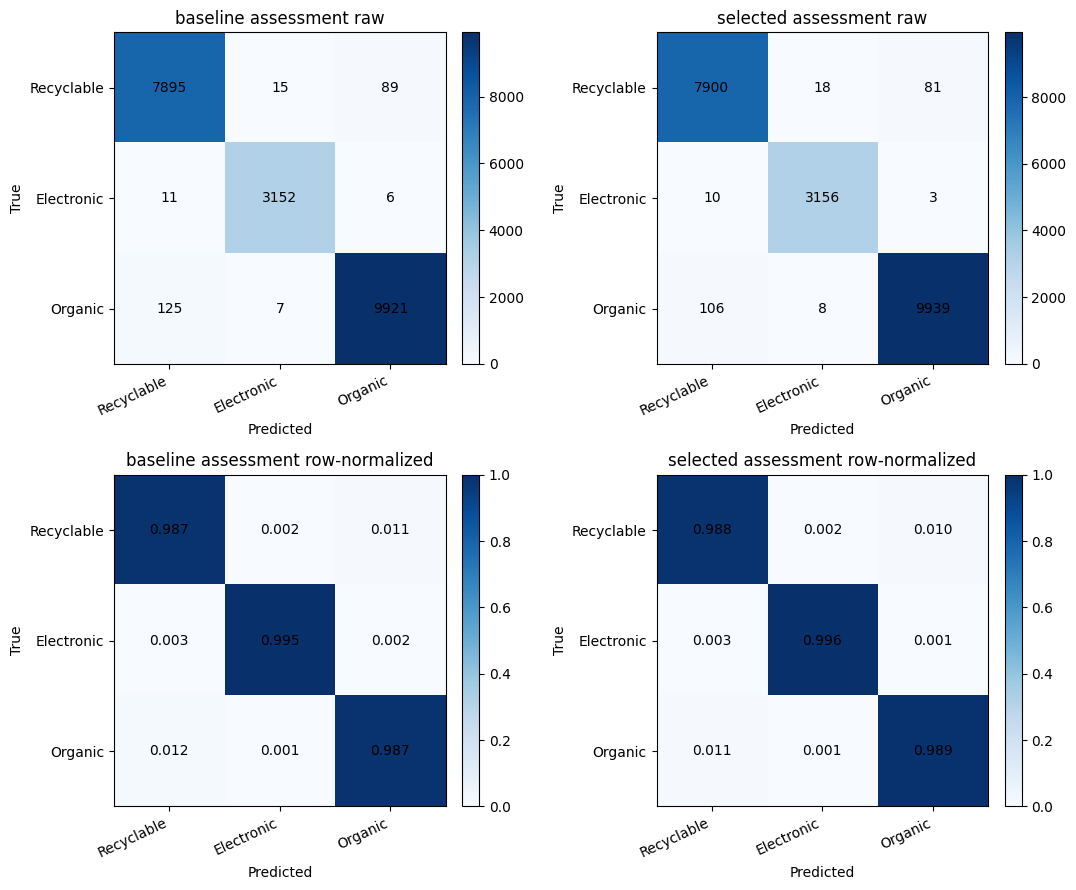

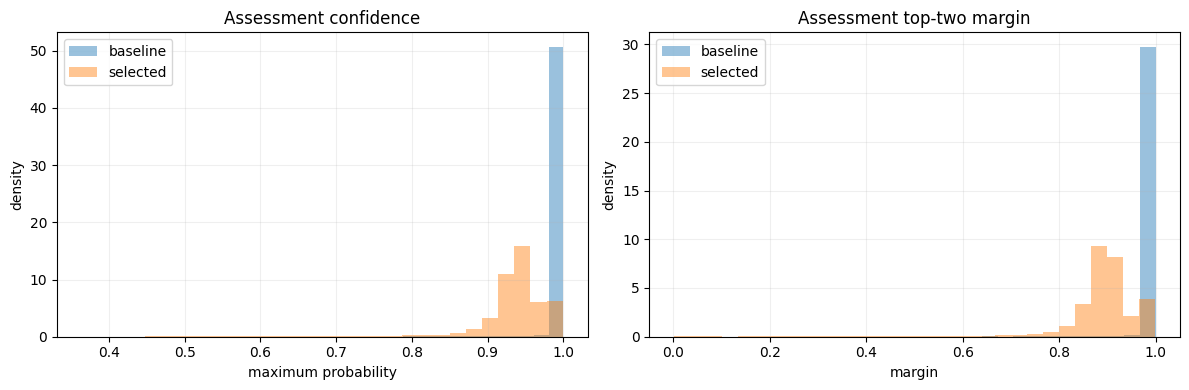

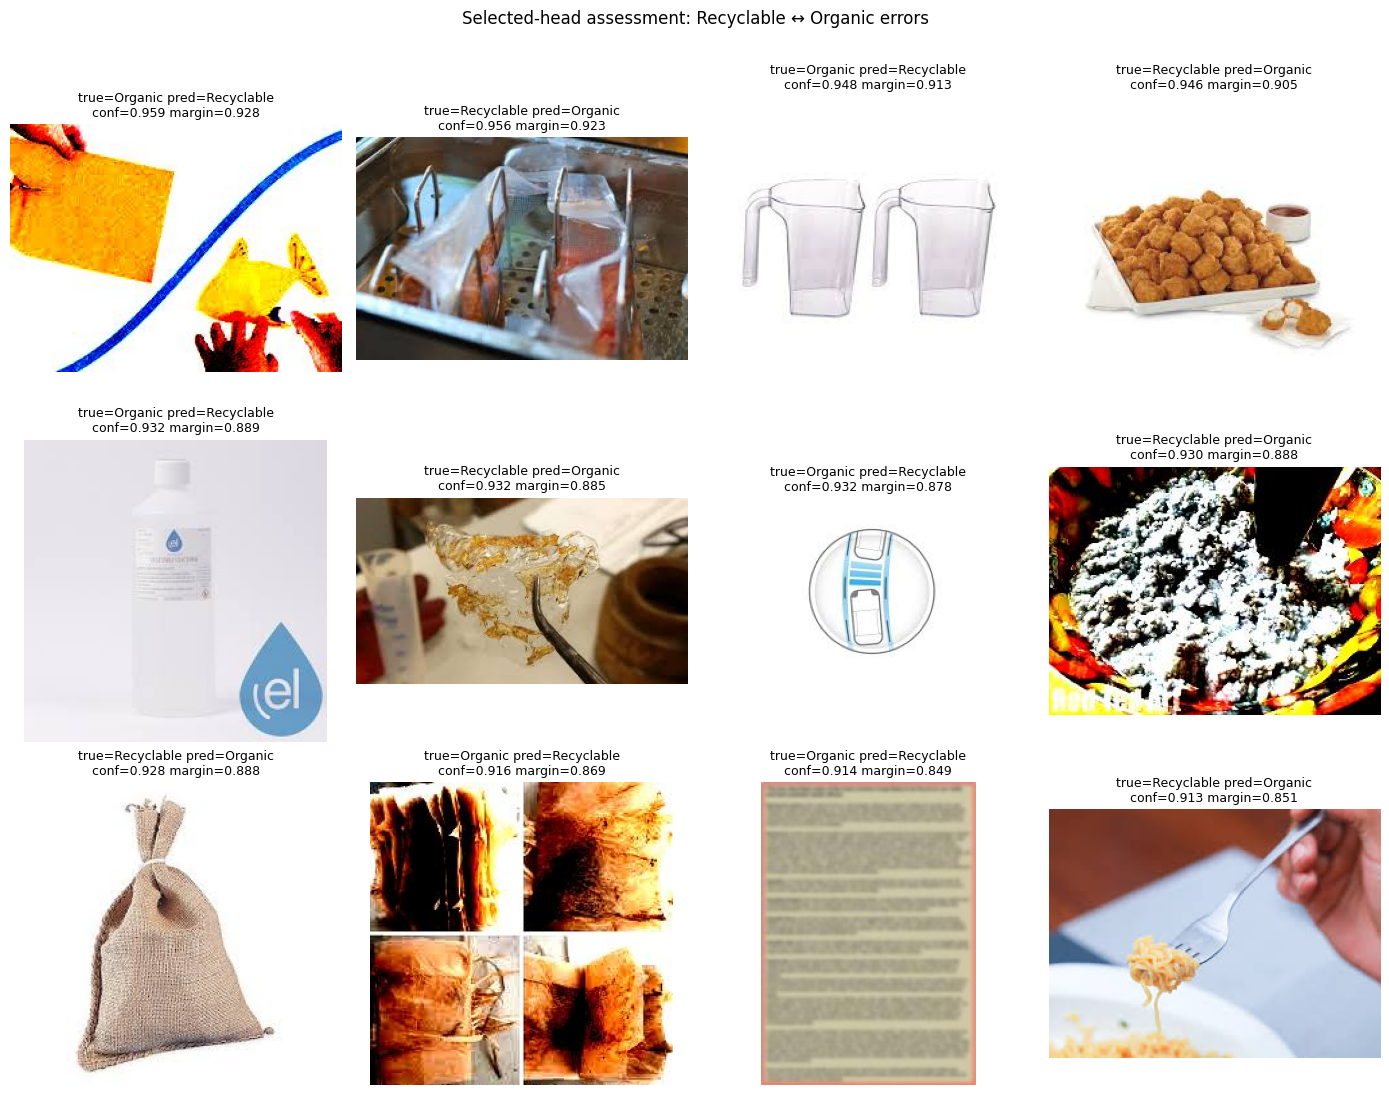

,experiment,scope,macro_f1,protocol_note
0,v5 ViT-L project reference,fold 0,0.985022,project reference; prior resolution/precision/...
1,v6 ViT-H+ project reference,fold 0,0.985188,384px FP32 final-layer project reference; not ...
2,v7 ViT-7B baseline_mlp_final,fold 0,0.987818,native 256px FP16; official pretrained final L...
3,v5 ViT-L project reference,assessment folds 1-4,0.986432,project reference; prior views/seeds differ
4,v7 ViT-7B baseline_mlp_final,assessment folds 1-4,0.989190,native 256px FP16 frozen assessment; official ...
5,v7 ViT-7B selected regularized_mlp_final,assessment folds 1-4,0.990191,architecture fixed after fold-0 selection; off...


,row_index,image_id,label,prediction,prob_0,prob_1,prob_2,confidence,top_two_margin,correct,fold,candidate,stage
19224,24056,2_Organic/O_7776.jpg,2,1,0.008233,0.983155,0.008612,0.983155,0.974542,False,4,regularized_mlp_final,assessment_selected
19154,23974,2_Organic/O_7701.jpg,2,1,0.012194,0.964504,0.023302,0.964504,0.941203,False,4,regularized_mlp_final,assessment_selected
20515,25648,2_Organic/O_9208.jpg,2,0,0.958728,0.030922,0.010350,0.958728,0.927805,False,1,regularized_mlp_final,assessment_selected
6316,7901,0_Recyclable/R_811.jpg,0,2,0.009770,0.033745,0.956484,0.956484,0.922739,False,1,regularized_mlp_final,assessment_selected
6490,8106,0_Recyclable/R_8295.jpg,0,1,0.029685,0.954357,0.015958,0.954357,0.924673,False,1,regularized_mlp_final,assessment_selected
14116,17583,2_Organic/O_1949.jpg,2,0,0.947591,0.034205,0.018204,0.947591,0.913386,False,2,regularized_mlp_final,assessment_selected
7799,9750,0_Recyclable/R_9775.jpg,0,2,0.012798,0.040969,0.946233,0.946233,0.905264,False,4,regularized_mlp_final,assessment_selected
2488,3140,0_Recyclable/R_3825.jpg,0,1,0.046702,0.940559,0.012740,0.940559,0.893857,False,4,regularized_mlp_final,assessment_selected
2403,3038,0_Recyclable/R_3733.jpg,0,1,0.051623,0.937091,0.011286,0.937091,0.885469,False,4,regularized_mlp_final,assessment_selected
13987,17426,2_Organic/O_1807.jpg,2,0,0.932386,0.043743,0.023871,0.932386,0.888643,False,2,regularized_mlp_final,assessment_selected


In [11]:
def normalized_confusion(matrix):
    matrix = np.asarray(matrix, dtype=np.float64)
    row_sums = matrix.sum(axis=1, keepdims=True)
    return np.divide(matrix, row_sums, out=np.zeros_like(matrix), where=row_sums > 0)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for column, (role, metrics) in enumerate((('baseline', baseline_assessment_metrics), ('selected', selected_assessment_metrics))):
    raw_matrix = np.asarray(metrics['confusion_matrix'])
    normalized_matrix = normalized_confusion(raw_matrix)
    for row, (matrix, title, value_format) in enumerate(((raw_matrix, 'raw', 'd'), (normalized_matrix, 'row-normalized', '.3f'))):
        axis = axes[row, column]
        image = axis.imshow(matrix, cmap='Blues', vmin=0, vmax=None if row == 0 else 1)
        axis.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=25, ha='right')
        axis.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        axis.set_xlabel('Predicted')
        axis.set_ylabel('True')
        axis.set_title('{} assessment {}'.format(role, title))
        for true_label in range(NUM_CLASSES):
            for predicted_label in range(NUM_CLASSES):
                value = matrix[true_label, predicted_label]
                rendered = format(int(value), value_format) if value_format == 'd' else format(value, value_format)
                axis.text(predicted_label, true_label, rendered, ha='center', va='center')
        fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'assessment_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, table, color in (
    ('baseline', baseline_assessment_predictions, 'tab:blue'),
    ('selected', selected_assessment_predictions, 'tab:orange'),
):
    axes[0].hist(table['confidence'], bins=30, alpha=0.45, density=True, label=role, color=color)
    axes[1].hist(table['top_two_margin'], bins=30, alpha=0.45, density=True, label=role, color=color)
axes[0].set(title='Assessment confidence', xlabel='maximum probability', ylabel='density')
axes[1].set(title='Assessment top-two margin', xlabel='margin', ylabel='density')
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'assessment_confidence_margin_distributions.png', dpi=160, bbox_inches='tight')
plt.show()

selected_errors = selected_assessment_predictions.loc[~selected_assessment_predictions['correct']].copy()
high_confidence_errors = selected_errors.loc[selected_errors['confidence'] >= 0.90].sort_values(['confidence', 'top_two_margin'], ascending=False)
write_csv_atomic(high_confidence_errors, ARTIFACT_DIR / 'selected_assessment_high_confidence_errors.csv')

pairwise_mask = (
    ((selected_errors['label'] == 0) & (selected_errors['prediction'] == 2))
    | ((selected_errors['label'] == 2) & (selected_errors['prediction'] == 0))
)
gallery_rows = selected_errors.loc[pairwise_mask].sort_values(['confidence', 'top_two_margin'], ascending=False).head(12).copy()
write_csv_atomic(gallery_rows, ARTIFACT_DIR / 'selected_assessment_recyclable_organic_gallery.csv')
if len(gallery_rows):
    path_by_image_id = dict(zip(run_df['image_id'], run_df['path']))
    columns = 4
    rows = math.ceil(len(gallery_rows) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(14, 3.6 * rows))
    axes = np.asarray(axes).reshape(-1)
    for axis, (_, row) in zip(axes, gallery_rows.iterrows()):
        with Image.open(path_by_image_id[row['image_id']]) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            axis.imshow(image)
        axis.set_title('true={} pred={}\nconf={:.3f} margin={:.3f}'.format(
            CLASS_NAMES[int(row['label'])], CLASS_NAMES[int(row['prediction'])], row['confidence'], row['top_two_margin']
        ), fontsize=9)
        axis.axis('off')
    for axis in axes[len(gallery_rows):]:
        axis.axis('off')
    fig.suptitle('Selected-head assessment: Recyclable ↔ Organic errors', y=1.01)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / 'selected_assessment_recyclable_organic_gallery.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No Recyclable ↔ Organic assessment errors to display.')

BASELINE_COMPARISON = pd.DataFrame([
    {
        'experiment': 'v5 ViT-L project reference',
        'scope': 'fold 0',
        'macro_f1': V5_REFERENCE_FOLD0_MACRO_F1,
        'protocol_note': 'project reference; prior resolution/precision/views/seeds differ',
    },
    {
        'experiment': 'v6 ViT-H+ project reference',
        'scope': 'fold 0',
        'macro_f1': V6_REFERENCE['fold0_macro_f1'],
        'protocol_note': '384px FP32 final-layer project reference; not causal',
    },
    {
        'experiment': 'v7 ViT-7B baseline_mlp_final',
        'scope': 'fold 0',
        'macro_f1': baseline_development_metrics['macro_f1'],
        'protocol_note': 'native 256px FP16; official pretrained final LayerNorm per token before final-block CLS/true-patch pooling',
    },
    {
        'experiment': 'v5 ViT-L project reference',
        'scope': 'assessment folds 1-4',
        'macro_f1': V5_REFERENCE_ASSESSMENT_FOLDS_1_TO_4_MACRO_F1,
        'protocol_note': 'project reference; prior views/seeds differ',
    },
    {
        'experiment': 'v7 ViT-7B baseline_mlp_final',
        'scope': 'assessment folds 1-4',
        'macro_f1': baseline_assessment_metrics['macro_f1'],
        'protocol_note': 'native 256px FP16 frozen assessment; official pretrained final LayerNorm per token before final-block CLS/true-patch pooling',
    },
    {
        'experiment': 'v7 ViT-7B selected {}'.format(SELECTED_HEAD),
        'scope': 'assessment folds 1-4',
        'macro_f1': selected_assessment_metrics['macro_f1'],
        'protocol_note': 'architecture fixed after fold-0 selection; official-final-normed cached readout',
    },
])
write_csv_atomic(BASELINE_COMPARISON, ARTIFACT_DIR / 'baseline_comparison_table.csv')
display(BASELINE_COMPARISON)

RUNTIME_AND_MEMORY_SUMMARY = {
    'model_load_seconds': MODEL_LOAD_SECONDS,
    'preflight_throughput_images_per_second': PREFLIGHT_REPORT['stages']['C_raw_train_throughput']['images_per_second'],
    'preflight_estimated_full_train_hours': PREFLIGHT_REPORT['stages']['C_raw_train_throughput']['estimated_full_train_hours'],
    'feature_cache_session_seconds': EXTRACTION_SECONDS,
    'feature_rows_written': extracted_rows,
    'feature_rows_reused': reused_rows,
    'head_training_seconds_total': sum(metrics['training_seconds'] for metrics in development_metrics + assessment_run_metrics),
    'preflight_gpu_memory': PREFLIGHT_REPORT['stages']['B_sharded_token_memory_audit']['gpu_memory'],
    'extraction_final_gpu_memory': shard_records[-1]['gpu_memory'],
    'post_backbone_release_gpu_memory': MODEL_RELEASE_GPU_MEMORY,
    'host_rss_gib_after_assessment': host_rss_gib(),
    'notebook_elapsed_seconds_so_far': time.perf_counter() - NOTEBOOK_STARTED_AT,
}
write_json_atomic(RUNTIME_AND_MEMORY_SUMMARY, ARTIFACT_DIR / 'runtime_and_memory_summary.json')
display(high_confidence_errors.head(30))

## 12. Fixed decision gates and final run manifest

The final artifact separates backbone signal from readout gain and untouched assessment. These project gates were fixed before results; they are practical decisions, not significance claims. The notebook stops here without test inference, submission work, test-time augmentation, calibration, adaptation, relabeling, or another experiment.

In [12]:
fold0_baseline_f1 = baseline_development_metrics['macro_f1']
assessment_selected_f1 = selected_assessment_metrics['macro_f1']
if fold0_baseline_f1 >= BACKBONE_STRONG_SIGNAL_THRESHOLD:
    backbone_gate = 'strong backbone signal'
elif fold0_baseline_f1 >= BACKBONE_STOP_THRESHOLD:
    backbone_gate = 'insufficient backbone return unless selected frozen head also validates strongly on folds 1-4'
else:
    backbone_gate = 'stop backbone scaling'
if assessment_selected_f1 >= ASSESSMENT_VIABLE_THRESHOLD:
    assessment_gate = 'viable main frozen 7B pipeline'
else:
    assessment_gate = 'do not justify ViT-7B as the main pipeline solely from model scale'

EXPERIMENT_DECISION = {
    'schema_version': 1,
    'revision_marker': V7_REVISION_MARKER,
    'experiment': EXPERIMENT_NAME,
    'experiment_purpose': EXPERIMENT_PURPOSE,
    'project_gates_are_statistical_significance_claims': False,
    'feasibility_runtime_evidence': {
        'preflight_passed': PREFLIGHT_REPORT['pass'],
        'two_t4_device_map': DEVICE_MAP,
        'throughput_images_per_second': PREFLIGHT_REPORT['stages']['C_raw_train_throughput']['images_per_second'],
        'minimum_throughput_images_per_second': MIN_EXTRACTION_IMAGES_PER_SECOND,
        'estimated_full_train_hours': PREFLIGHT_REPORT['stages']['C_raw_train_throughput']['estimated_full_train_hours'],
        'feature_cache_complete': FEATURE_CACHE_MANIFEST['complete'],
    },
    'backbone_baseline_result': {
        'head': 'baseline_mlp_final',
        'representation': 'official pretrained final LayerNorm per token before final-block CLS/true-patch pooling',
        'development_fold': DEVELOPMENT_FOLD,
        'macro_f1': fold0_baseline_f1,
        'accuracy': baseline_development_metrics['accuracy'],
        'multiclass_log_loss': baseline_development_metrics['multiclass_log_loss'],
        'gate': backbone_gate,
    },
    'head_readout_result': {
        'selected_head': SELECTED_HEAD,
        'selected_fold0_macro_f1': selected_development_metrics['macro_f1'],
        'fold0_gain_over_baseline': selected_development_metrics['macro_f1'] - fold0_baseline_f1,
        'minimum_nonbaseline_gain': MIN_NONBASELINE_HEAD_GAIN,
        'selection_reason': selection_reason,
    },
    'untouched_assessment_result': {
        'folds': list(ASSESSMENT_FOLDS),
        'baseline_macro_f1': baseline_assessment_metrics['macro_f1'],
        'selected_macro_f1': assessment_selected_f1,
        'selected_accuracy': selected_assessment_metrics['accuracy'],
        'selected_multiclass_log_loss': selected_assessment_metrics['multiclass_log_loss'],
        'gate': assessment_gate,
    },
    'project_reference_comparisons': {
        'v6_vithplus_fold0_macro_f1': V6_REFERENCE['fold0_macro_f1'],
        'v5_vitl_fold0_macro_f1': V5_REFERENCE_FOLD0_MACRO_F1,
        'v5_vitl_folds1_4_macro_f1': V5_REFERENCE_ASSESSMENT_FOLDS_1_TO_4_MACRO_F1,
    },
    'comparability_limitations': [
        'V7 is native 256px FP16 with the official pretrained final LayerNorm applied per token before CLS/true-patch pooling for each cached late block.',
        'Prior project references used different resolution, precision, views, and/or seed aggregation.',
        'Numerical differences are project decision evidence, not protocol-matched causal backbone effects.',
    ],
    'follow_up_launched': False,
    'prohibited_follow_up_actions_performed': [],
}
write_json_atomic(EXPERIMENT_DECISION, ARTIFACT_DIR / 'experiment_decision.json')

top_level_artifacts = sorted(path.name for path in ARTIFACT_DIR.iterdir() if path.is_file())
head_artifacts = sorted(path.name for path in HEADS_DIR.iterdir() if path.is_file())
safe_image_count = sum(1 for path in (ARTIFACT_DIR / 'safe_images').rglob('*') if path.is_file()) if (ARTIFACT_DIR / 'safe_images').exists() else 0
RUN_MANIFEST = {
    'schema_version': 1,
    'revision_marker': V7_REVISION_MARKER,
    'experiment_name': EXPERIMENT_NAME,
    'experiment_purpose': EXPERIMENT_PURPOSE,
    'cached_representation': 'official pretrained final LayerNorm per token before CLS/true-patch pooling',
    'locked_contract': LOCKED_CONTRACT,
    'locked_contract_signature': LOCKED_CONTRACT_SIGNATURE,
    'environment': ENVIRONMENT_INFO,
    'gpus': GPU_RUNTIME_INFO,
    'model_and_preprocess': MODEL_AND_PREPROCESS_AUDIT,
    'data_and_fold_signature': DATA_AND_FOLD_SIGNATURE,
    'preflight_contract_signature': PREFLIGHT_CONTRACT_SIGNATURE,
    'feature_cache_signature': CACHE_SIGNATURE,
    'feature_cache_complete': FEATURE_CACHE_MANIFEST['complete'],
    'head_candidates': list(CANDIDATE_NAMES),
    'selected_head': SELECTED_HEAD,
    'head_selection': HEAD_SELECTION,
    'backbone_baseline_fold0_metrics': baseline_development_metrics,
    'selected_head_fold0_metrics': selected_development_metrics,
    'baseline_assessment_metrics': baseline_assessment_metrics,
    'selected_assessment_metrics': selected_assessment_metrics,
    'runtime_and_memory_summary': RUNTIME_AND_MEMORY_SUMMARY,
    'experiment_decision': EXPERIMENT_DECISION,
    'competition_compliance': {
        'development_data': 'official labeled raw train images only',
        'visual_information_only': True,
        'external_labels_used': False,
        'public_pretrained_model_documented': MODEL_ID,
        'official_class_codes': {str(index): name for index, name in enumerate(CLASS_NAMES)},
        'prediction_features': 'official-final-normed per-token visual backbone representations pooled as CLS/true-patch mean only',
        'competition_test_accessed': False,
        'submission_created': False,
    },
    'artifact_inventory': {
        'top_level_files': sorted(set(top_level_artifacts + ['run_manifest.json'])),
        'head_files': head_artifacts,
        'feature_shard_count': len(shard_records),
        'safe_image_count': safe_image_count,
    },
    'runtime_risks_checked_only_on_kaggle': [
        'gated ViT-7B checkpoint access and immutable revision availability',
        'Transformers/Accelerate compatibility with the official model implementation',
        'balanced two-T4 placement with no CPU or disk modules',
        'FP16 finiteness and exact official token layout',
        'actual throughput, VRAM headroom, host memory, and multi-hour session stability',
    ],
    'notebook_elapsed_seconds': time.perf_counter() - NOTEBOOK_STARTED_AT,
}
write_json_atomic(RUN_MANIFEST, ARTIFACT_DIR / 'run_manifest.json')
print(json.dumps(EXPERIMENT_DECISION, indent=2))
print('V7 complete. Train-only artifacts:', ARTIFACT_DIR)

{
  "schema_version": 1,
  "revision_marker": "v7_official_final_norm_before_pooling_v2",
  "experiment": "v7_dinov3_vit7b_frozen_raw",
  "experiment_purpose": "native-resolution ViT-7B frozen feasibility/performance experiment",
  "project_gates_are_statistical_significance_claims": false,
  "feasibility_runtime_evidence": {
    "preflight_passed": true,
    "two_t4_device_map": {
      "embeddings": "cuda:0",
      "rope_embeddings": "cuda:0",
      "layer.0": "cuda:0",
      "layer.1": "cuda:0",
      "layer.2": "cuda:0",
      "layer.3": "cuda:0",
      "layer.4": "cuda:0",
      "layer.5": "cuda:0",
      "layer.6": "cuda:0",
      "layer.7": "cuda:0",
      "layer.8": "cuda:0",
      "layer.9": "cuda:0",
      "layer.10": "cuda:0",
      "layer.11": "cuda:0",
      "layer.12": "cuda:0",
      "layer.13": "cuda:0",
      "layer.14": "cuda:0",
      "layer.15": "cuda:0",
      "layer.16": "cuda:0",
      "layer.17": "cuda:0",
      "layer.18": "cuda:0",
      "layer.19": "cuda:0",
